# Instant Insanity on a quantum computer: 12 qubits, two quantum searches, every answer checked

**Team:** Kiarash Naghavi Khanghah, Luis A. Mendez, Hoang Anh Nguyen. **Level reached:** Warm-up, Core and Bonus (N cubes, N colours).
Qiskit Fall Fest Connecticut 2026, qBraid challenge.

**What is quantum here and what is not.** We store a whole tower choice in 12 qubits (3 per cube) and use two quantum
search methods on that register: QAOA with a mixer that only moves between the 6 legal choices of each cube, and
Grover search with an oracle written only from the puzzle rules. Everything else is classical: the brute-force
checker, the training of the QAOA angles (a classical simulation of the 1,296 legal cases), and the final check of
every tower a shot decodes to. A classical computer solves the 4-cube puzzle in a fraction of a second; we do not
claim a speedup, we measure how often each circuit lands on the answer and how many gates it costs.

**How to read this notebook.** Each section starts with a short plain-words explanation, then the code, then the
printed checks. All heavy code lives in `src/` (short, documented functions); the notebook calls it in order.

## 0. Settings and setup

The switches in the next cell control the whole notebook:

* `USE_QBRAID = False`: every circuit runs on the local Aer simulator. Nothing is sent to qBraid and no credits are
  spent. The real SV1 results are replayed from saved counts (`REPLAY_SV1 = True`, see the box below).
* `RUN_HEAVY = False`: the three largest Bonus runs (N = 6, 7, 8 cubes, up to 26 qubits, about 15 minutes in total)
  are read from `results/heavy_rows.json`, which `scripts/run_heavy.py` wrote with the same code and seed. The notebook
  re-checks their exact success probabilities live. Set it to `True` to recompute them here.
* `SEED = 7`: the one random seed used everywhere (simulator, transpiler, NumPy), as in the starter notebook.

> **qBraid SV1 runs (done, replayed here).** Four rows (C2, G2, W1, N5) were run once on the qBraid SV1 simulator
> `aws:aws:sim:sv1` with `python scripts/run_sv1.py --jobs C2 G2 W1 N5 --yes-spend-credits` (0.375 credits each).
> Their counts are saved in `results/sv1_counts/<tag>.json` together with a SHA-256 fingerprint of the exact
> transpiled circuit. With `REPLAY_SV1 = True` (below) section 13 rebuilds each circuit and replays the saved counts
> only if the fingerprint, device and shot count all match; then it decodes them with the same checked decoders as the
> local rows and adds a separate row (for example `C2-SV1`) with the SV1 device and job id. Replay sends nothing and
> spends no credits. `USE_QBRAID = False` stays off, so executing this notebook never submits a job; flipping it would
> send every row (11 paid jobs) and is not recommended. The submission code only accepts `aws:aws:sim:sv1`, refuses
> any `:qpu:` device, needs a price quote and never prints credentials. Rigetti hardware jobs were sent by a separate
> script (`scripts/run_qpu.py`); section 14 only reads their saved counts.

In [1]:
USE_QBRAID = False   # True sends circuits to qBraid SV1 (costs credits); see the box above
REPLAY_SV1 = True    # replay the saved SV1 counts (same circuit fingerprint, device, shots); no job, no credits
RUN_HEAVY = False    # True recomputes the N = 6, 7, 8 Bonus rows here (about 15 minutes)
SEED = 7
SHOTS_N4 = 4000      # shots for every 4-cube row
SHOTS_BONUS = 2000   # shots for every Bonus row

In [2]:
import importlib.util
import subprocess
import sys

# install only what is missing (qBraid Lab already has almost everything); never upgrade an imported package
NEEDED = {"qiskit": "qiskit>=1.3,<3", "qiskit_aer": "qiskit-aer>=0.15", "qbraid": "qbraid[qiskit]>=0.12,<0.14",
          "matplotlib": "matplotlib", "networkx": "networkx", "scipy": "scipy", "pylatexenc": "pylatexenc"}
missing = [spec for mod, spec in NEEDED.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
print("installed:", ", ".join(missing) or "nothing, everything was already here")

installed: nothing, everything was already here


In [3]:
import inspect
import itertools
import json
import time
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import qiskit
import qiskit_aer
from IPython.display import Markdown, display
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import Statevector, state_fidelity
from scipy.sparse import SparseEfficiencyWarning

import resources.helpers as helpers
from resources.helpers import (CIRCUIT, diagonal, draw_graph, draw_nets, draw_tower, plot_cost_counts,
                               plot_history, plot_landscape, plot_top_counts, prepare, show, solution_strings,
                               strip_marker, tower_from)
from src import puzzle, warmup, compact, grover, runtime, report
from src.puzzle import (ALT4, BONUS, CHOICES, COLOURS, CUBES, all_solutions, baseline, brute_force_towers, cost,
                        cost_table, count_answers, front_back, instance, is_two_factor, make_puzzle, one_hot,
                        solves, verify_choice)
from src.warmup import (build_hamiltonian, constrained_qaoa, decode_frontback, decode_onehot, energy,
                        front_back_hamiltonian, good_strings, onehot_qaoa, optimise_warmup, scan, to_bits)
from src.compact import (Reduced, angles_for, check_hamiltonian, choice_from_codes, codes_from_key, compact_hamiltonian,
                         compact_qaoa, cube_mixer, decode_tower, key_from_codes, load_angles, ramp_angles,
                         transfer_table, train_layerwise, uniform6, valid_indices)
from src.grover import (build_oracle, grover_circuit, grover_iterations, grover_success, marked_states,
                        oracle_expression, resource_estimate)
from src.runtime import (BASIS, SV1, aer_counts, circuit_metrics, prepare_safe, prepared, run_on_qbraid,
                         strip_marker_safe, trace_transpile)
from src.report import make_row, results_table, save_results, success_rate

runtime.USE_QBRAID = USE_QBRAID          # the switch above is the only place this is set
runtime.REPLAY_SV1 = REPLAY_SV1
warnings.filterwarnings("ignore", category=SparseEfficiencyWarning)   # harmless scipy notice from exact simulation
np.random.seed(SEED)
FIG = Path("results/figures"); FIG.mkdir(parents=True, exist_ok=True)
ROWS = []                                # every results-table row, created only by make_row
FACTS = {}                               # extra measured numbers for the slides (results/facts.json)


def save_show(fig, name):
    # save a figure for the slides, then show it inline
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight", facecolor="white")
    show(fig)


def save_drawing(draw, name, *args, **kwargs):
    # run a helpers drawing function and also save the picture it shows
    original = helpers.show
    def keep(fig):
        fig.savefig(FIG / name, dpi=150, bbox_inches="tight", facecolor="white")
        original(fig)
    helpers.show = keep
    try:
        draw(*args, **kwargs)
    finally:
        helpers.show = original


def add_row(row):
    ROWS.append(row)
    return row


print("python", sys.version.split()[0], "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__,
      "| Grover oracle backend:", grover.ORACLE_BACKEND, "(synthesis on Qiskit 2.x; diagonal fallback on 1.3)")
print("USE_QBRAID =", runtime.USE_QBRAID, "| REPLAY_SV1 =", runtime.REPLAY_SV1, "| RUN_HEAVY =", RUN_HEAVY, "| SEED =", SEED)

python 3.12.15 | qiskit 2.6.0 | qiskit-aer 0.17.2 | Grover oracle backend: synthesis (synthesis on Qiskit 2.x; diagonal fallback on 1.3)
USE_QBRAID = False | REPLAY_SV1 = True | RUN_HEAVY = False | SEED = 7


## 1. The puzzle and the classical answer

Four cubes, each face painted red (R), green (G), blue (B) or yellow (Y). Stack them in a tower so that each of the
four long sides (front, right, back, left) shows all four colours exactly once. A cube is described by its three
pairs of opposite faces: `["GR", "BR", "GY"]` means green is opposite red, blue opposite red, green opposite yellow.

A cube can sit in 24 ways, so there are 24^4 = 331,776 towers. A laptop checks them all in well under a second. That
is our classical reference: the quantum circuits below are not faster; the point is to see how a quantum search finds
the same answer and what it costs in qubits and gates.

CUBES = [['GR', 'BR', 'GY'], ['GY', 'RB', 'BY'], ['BR', 'RG', 'RY'], ['YR', 'RG', 'BG']]


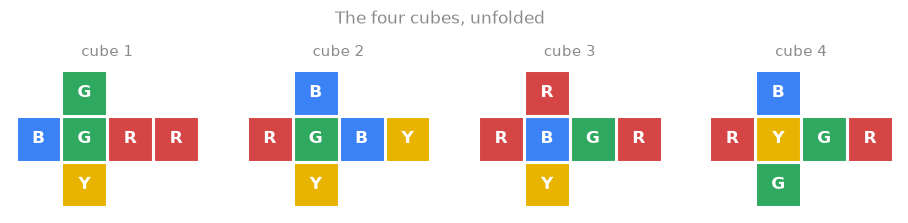

brute force: checked 331,776 towers in 0.15 s, found 8 solved ones
every one passes solves(): True


In [4]:
print("CUBES =", CUBES)
draw_nets(CUBES)
start = time.perf_counter()
winners = brute_force_towers(CUBES)
bf_seconds = time.perf_counter() - start
print(f"brute force: checked {24 ** len(CUBES):,} towers in {bf_seconds:.2f} s, found {len(winners)} solved ones")
print("every one passes solves():", all(solves(t) for t in winners))
FACTS["brute_force"] = {"towers": 24 ** len(CUBES), "solved": len(winners), "seconds": round(bf_seconds, 3)}

The 8 solved towers are really one tower: it can be rotated 4 ways and flipped upside down, which gives 8 positions
that all look solved. So the puzzle has exactly one answer.

## 2. The graph view: 6 choices per cube

Draw one dot per colour and one line per opposite pair (12 lines). For a tower, each cube chooses one pair for the
front/back axis and a different pair for the left/right axis; the third pair is hidden on top and bottom. So each cube
has only **6 legal choices** (an ordered pair of two different pair numbers), and the whole puzzle has 6^4 = 1,296
cases instead of 331,776.

Front and back together must show each colour twice, so the 4 front/back lines must touch every colour exactly twice
(a "2-factor"). The same holds for left/right, and the two sets of lines must use different pairs of each cube.

CHOICES (code k -> (front/back pair, left/right pair)): [(0, 1), (0, 2), (1, 0), (1, 2), (2, 0), (2, 1)]
4 of 81 front/back picks are 2-factors: [(0, 2, 2, 2), (1, 0, 2, 2), (2, 1, 2, 2), (2, 2, 0, 1)]


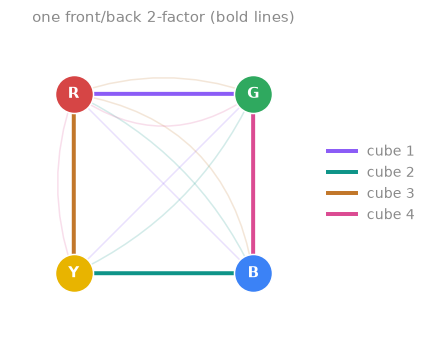

2 of 1,296 graph-level cases solve the puzzle; count_answers says 2
  choice [(2, 1), (2, 0), (0, 2), (1, 2)] -> tower [('G', 'B', 'Y', 'R'), ('Y', 'Y', 'B', 'G'), ('B', 'R', 'R', 'Y'), ('R', 'G', 'G', 'B')] | solves: True
  choice [(1, 2), (0, 2), (2, 0), (2, 1)] -> tower [('B', 'G', 'R', 'Y'), ('Y', 'Y', 'G', 'B'), ('R', 'B', 'Y', 'R'), ('G', 'R', 'B', 'G')] | solves: True


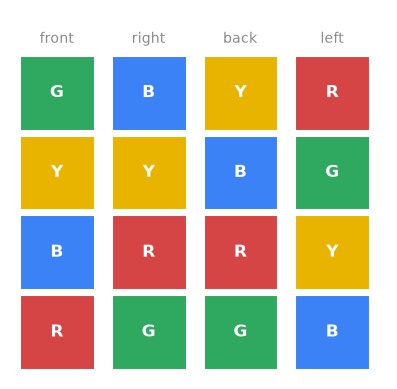

In [5]:
print("CHOICES (code k -> (front/back pair, left/right pair)):", CHOICES)
print(f"{len(front_back)} of {3 ** len(CUBES)} front/back picks are 2-factors:", front_back)
save_drawing(draw_graph, "graph_N4.png", CUBES, front_back[0], "one front/back 2-factor (bold lines)")
answers = all_solutions(CUBES)
print(f"{len(answers)} of {6 ** len(CUBES):,} graph-level cases solve the puzzle; count_answers says {count_answers(CUBES)}")
for choice in answers:
    tower = tower_from(CUBES, choice)
    print("  choice", choice, "-> tower", tower, "| solves:", solves(tower))
save_drawing(draw_tower, "tower_N4.png", tower_from(CUBES, answers[0]))

The two graph-level answers are the same tower turned a quarter turn (front/back and left/right swap roles). Both
are counted as correct everywhere below, and both pass the starter's `solves` check.

## 3. Classical checks of the model (before any quantum run)

Before trusting a quantum circuit we check that the maths it optimises is right. Four checks:

1. **The starter's cost function.** For every one of the 3^4 x 3^4 = 6,561 "one pair per axis" candidates, the cost
   is zero exactly for the 2 answers, and every wrong candidate costs at least 2.
2. **The starter's 24-qubit Hamiltonian** (the quantum version of the cost) gives the same number as the cost on 200
   random bitstrings, including broken ones, and is zero on the two known answer bitstrings.
3. **Bit order.** In Qiskit, qubit 0 is the *rightmost* character of a result string. We decode the two known answer
   strings, and check that reading them backwards does not give a tower.
4. **The marker trap.** Providers may return strings in either order. The starter adds one marker qubit fixed to 1 to
   detect this, but if data qubit 0 is also always 1, the marker is ambiguous and the decoding silently goes wrong. We
   show that case and our fix (a two-sided marker: one qubit fixed to 0 at one end, one fixed to 1 at the other).

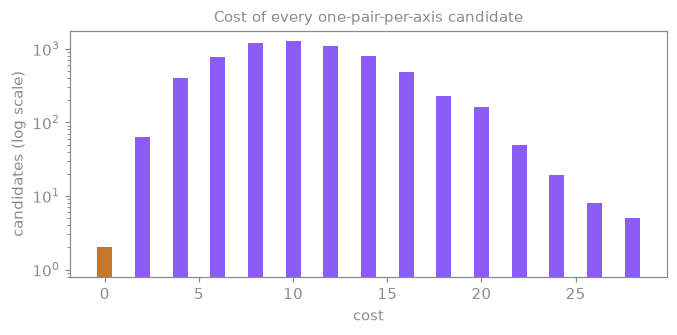

6,561 candidates, 2 at cost 0, lowest nonzero cost 2


In [6]:
rng = np.random.default_rng(SEED)
scores = np.array([cost(CUBES, [one_hot(p) for p in fb], [one_hot(p) for p in lr])
                   for fb in itertools.product(range(3), repeat=4) for lr in itertools.product(range(3), repeat=4)])
plot_cost_counts(scores)
values = np.unique(scores)
print(f"{len(scores):,} candidates, {np.sum(scores == 0)} at cost 0, lowest nonzero cost {values[1]}")
FACTS["cost_check"] = {"candidates": int(len(scores)), "zeros": int(np.sum(scores == 0)), "min_nonzero": int(values[1])}

In [7]:
H_full = build_hamiltonian(CUBES)
print(f"starter one-hot Hamiltonian: {H_full.num_qubits} qubits, {len(H_full)} Pauli terms")
gaps = []
for _ in range(200):
    x = rng.integers(0, 2, (4, 3)).tolist()
    y = rng.integers(0, 2, (4, 3)).tolist()
    gaps.append(abs(energy(H_full, to_bits(x, y)) - cost(CUBES, x, y)))
print(f"200 random bitstrings (most of them not one-hot): largest gap between H and cost {max(gaps):.1e}")

KNOWN = ["010100001100100001100010", "100010100001001100010100"]   # the two answers, Qiskit order
for key in KNOWN:
    bits = [int(b) for b in reversed(key)]                        # bits[q] is qubit q
    choice = decode_onehot(key, 4)
    back = decode_onehot(key[::-1], 4)
    print(f"{key}: energy {energy(H_full, bits):.1f}, decodes to {choice}, verified {verify_choice(CUBES, choice)};"
          f" read backwards -> {back}, verified {back is not None and verify_choice(CUBES, back)}")

starter one-hot Hamiltonian: 24 qubits, 153 Pauli terms
200 random bitstrings (most of them not one-hot): largest gap between H and cost 0.0e+00
010100001100100001100010: energy 0.0, decodes to [(1, 2), (0, 2), (2, 0), (2, 1)], verified True; read backwards -> [(1, 0), (2, 0), (0, 2), (0, 1)], verified False
100010100001001100010100: energy 0.0, decodes to [(2, 1), (2, 0), (0, 2), (1, 2)], verified True; read backwards -> [(0, 1), (0, 2), (2, 0), (1, 0)], verified False


In [8]:
# the marker trap: data qubit 0 is always 1 here, data qubit 2 is random
demo = QuantumCircuit(3)
demo.x(0)
demo.h(2)
truth = {"001", "101"}                                # what the data really is, Qiskit order

raw = aer_counts(prepare(demo), 2000)                 # starter plumbing: one marker qubit set to 1
flipped = {k[::-1]: n for k, n in raw.items()}        # the same result from a provider that lists bits the other way
print("starter strip_marker, Qiskit order   :", sorted(strip_marker(raw)), "correct:", set(strip_marker(raw)) == truth)
print("starter strip_marker, reversed order :", sorted(strip_marker(flipped)), "correct:", set(strip_marker(flipped)) == truth)

raw2 = aer_counts(prepare_safe(demo), 2000)           # ours: qubit 0 fixed to 0, top qubit fixed to 1
flipped2 = {k[::-1]: n for k, n in raw2.items()}
print("strip_marker_safe, Qiskit order      :", sorted(strip_marker_safe(raw2)), "correct:", set(strip_marker_safe(raw2)) == truth)
print("strip_marker_safe, reversed order    :", sorted(strip_marker_safe(flipped2)), "correct:", set(strip_marker_safe(flipped2)) == truth)

starter strip_marker, Qiskit order   : ['001', '101'] correct: True
starter strip_marker, reversed order : ['001', '011'] correct: False
strip_marker_safe, Qiskit order      : ['001', '101'] correct: True
strip_marker_safe, reversed order    : ['001', '101'] correct: True


With the starter's single marker, the reversed result *also* starts with a 1 (because data qubit 0 is always 1), so it
is read as if it were in Qiskit order and comes out wrong without any error. This matters for us: in our best runs
almost every shot has qubit 0 equal to 1. The two-sided marker (`prepare_safe` / `strip_marker_safe` in `src/runtime.py`)
can never be confused, so every circuit we report goes through it. The starter's `prepare` and `strip_marker` are kept
unchanged in `resources/helpers.py`.

## 4. Warm-up: front/back only, 12 qubits (the starter's QAOA, condensed)

The warm-up only asks for the front/back half: pick one pair per cube so that every colour shows up twice. The starter
uses 3 qubits per cube (one per pair, "one-hot": exactly one of the three is 1).

QAOA (Quantum Approximate Optimisation Algorithm) alternates two steps p times: a **cost step** that gives each
bitstring a phase proportional to its cost, and a **mixer step** that moves amplitude between bitstrings. The angles
of the steps are tuned so that low-cost strings end up likely. The textbook version (Hadamards and RX mixers) finds a
good pick only 1.38 % of the time at p = 1 (starter notebook), because it wastes most of its probability on strings
that are not one-hot. The starter's better version starts in a W state (exactly one 1 per cube) and uses an XY mixer
that keeps it that way. We reproduce it: a p = 1 grid of angles, then COBYLA at p = 2.

warm-up Hamiltonian: 12 qubits, 68 Pauli terms; 4 good bitstrings: ['100100100001', '100100001010', '100100010100', '010001100100']


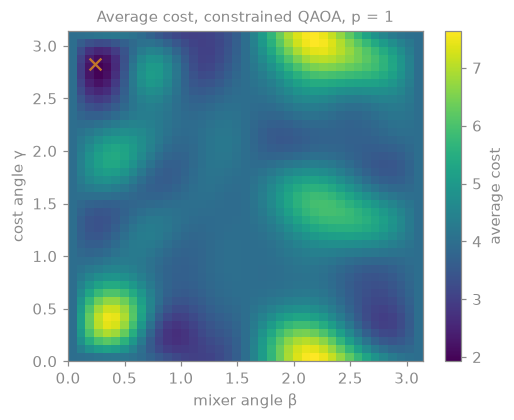

best p=1 angles gamma=2.827, beta=0.236: average cost 1.93, P(good pick) 18.8% (random valid pick 4.9%)


In [9]:
H_fb = front_back_hamiltonian(CUBES)
GOOD = good_strings(CUBES)
print(f"warm-up Hamiltonian: {H_fb.num_qubits} qubits, {len(H_fb)} Pauli terms; {len(GOOD)} good bitstrings:", GOOD)
gammas, betas = np.linspace(0, np.pi, 41), np.linspace(0, np.pi, 41)
avg, hit = scan(H_fb, gammas, betas, GOOD)
i, j = np.unravel_index(avg.argmin(), avg.shape)
g1, b1 = gammas[i], betas[j]
plot_landscape(avg, gammas, betas, (g1, b1))
FACTS["W1p1_noiseless"] = float(hit[i, j])   # one QAOA round at the grid optimum (the circuit sent to the QPU)
print(f"best p=1 angles gamma={g1:.3f}, beta={b1:.3f}: average cost {avg[i, j]:.2f}, P(good pick) {hit[i, j]:.1%}"
      f" (random valid pick {baseline(4, 'fb_valid'):.1%})")

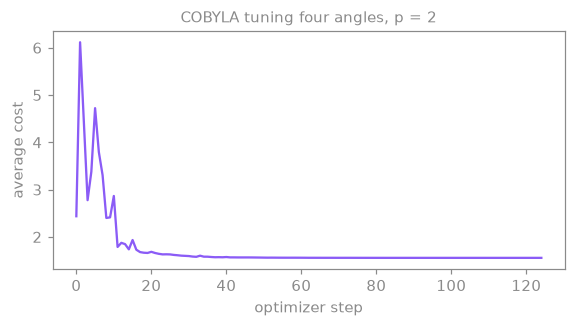

p=2 after 125 evaluations: average cost 1.56, exact P(good pick) 28.4%


In [10]:
best, history = optimise_warmup(H_fb, [g1, g1, b1, b1])
plot_history(history, "COBYLA tuning four angles, p = 2")
w1_circuit = constrained_qaoa(H_fb, best[:2], best[2:])
probs = Statevector(w1_circuit).probabilities()
w1_exact = float(sum(probs[int(s, 2)] for s in GOOD))
print(f"p=2 after {len(history)} evaluations: average cost {history[-1]:.2f}, exact P(good pick) {w1_exact:.1%}")

No qBraid job was sent, so this ran on the local Aer simulator.
W1: 1123 of 4000 shots are good front/back picks, P = 0.2807 +- 0.0071 (exact 0.2840); shots that are not one-hot: 0


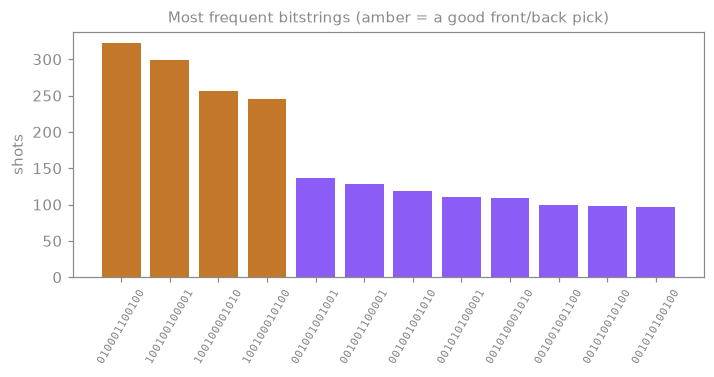

In [11]:
def good_pick(key):
    # a warm-up shot is good when it decodes to one pair per cube that forms a front/back 2-factor
    picks = decode_frontback(key, 4)
    return picks if picks is not None and is_two_factor(CUBES, picks) else None


counts = run_on_qbraid(w1_circuit, shots=SHOTS_N4, tag="W1", replay=False)
w1 = success_rate(counts, good_pick, valid=report.frontback_valid)
print(f"W1: {w1['n_good']} of {w1['n_total']} shots are good front/back picks, P = {w1['P']:.4f} +- {w1['se']:.4f}"
      f" (exact {w1_exact:.4f}); shots that are not one-hot: {w1['n_invalid']}")
plot_top_counts(counts, GOOD)
add_row(make_row("W1", "Warm-up", "N=4 front/back only", 4, "one-hot, 3 qubits per cube (front/back only)",
                 "W state + XY mixer QAOA, p=2 (COBYLA)", prepared(w1_circuit), SHOTS_N4, w1,
                 baseline(4, "fb_bits"), baseline(4, "fb_valid"), p_exact=w1_exact,
                 notes="a good front/back pick, not a full tower"));

This is a front/back pick, not a whole tower: the warm-up row is reported as "P(good pick)" and the notes say so.

## 5. Our encoding: 3 qubits per cube, 12 qubits in total

The starter's full model uses 6 qubits per cube (one-hot for front/back and one-hot for left/right): 24 qubits, of
which only 6^4 = 1,296 out of 2^24 = 16.8 million bitstrings are even legal. Instead we number the 6 legal choices of
a cube 0 to 5 and write that number in binary on 3 qubits. The whole tower choice is then 12 qubits, and 1,296 of
the 4,096 bitstrings are legal (codes 6 and 7 are the only illegal ones, and our circuits never produce them).

Cube c uses qubits 3c, 3c+1, 3c+2 (lowest bit first). Reading a result string, remember qubit 0 is on the right.

code k | bits (q2 q1 q0) | front/back pair | left/right pair | hidden pair
  0    |      000        |        0        |        1        |      2
  1    |      001        |        0        |        2        |      1
  2    |      010        |        1        |        0        |      2
  3    |      011        |        1        |        2        |      0
  4    |      100        |        2        |        0        |      1
  5    |      101        |        2        |        1        |      0

example: result string 011001100101 -> codes per cube [5, 4, 1, 3] -> choice [(2, 1), (2, 0), (0, 2), (1, 2)] -> solves: True
the same string read backwards -> [6, 4, 1, 5] -> decode_tower: None


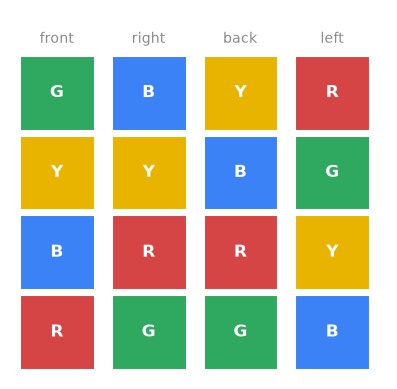

In [12]:
print("code k | bits (q2 q1 q0) | front/back pair | left/right pair | hidden pair")
for k, (fb, lr) in enumerate(CHOICES):
    print(f"  {k}    |      {k:03b}        |        {fb}        |        {lr}        |      {3 - fb - lr}")
key = "011001100101"
codes = codes_from_key(key, 4)
choice = choice_from_codes(codes)
print(f"\nexample: result string {key} -> codes per cube {codes} -> choice {choice} -> solves: {verify_choice(CUBES, choice)}")
print("the same string read backwards ->", codes_from_key(key[::-1], 4), "-> decode_tower:", decode_tower(CUBES, key[::-1]))
draw_tower(tower_from(CUBES, choice))

In [13]:
table = [("starter one-hot, 6 qubits per cube", 24, baseline(4, "bits6N"), baseline(4, "WxW")),
         ("compact, 3 qubits per cube (ours)", 12, baseline(4, "bits3N"), baseline(4, "valid6N"))]
print(f"{'encoding':38s} {'qubits':>6s} {'random bitstring':>18s} {'random start-subspace state':>28s}")
print("(one-hot start subspace = W x W, 9^4 strings, same-pair overlaps included; compact = the 6^4 valid placements)")
for name, q, b_bits, b_sub in table:
    print(f"{name:38s} {q:6d} {b_bits:18.3e} {b_sub:28.3e}")
FACTS["baselines_N4"] = {"bits6N": baseline(4, "bits6N"), "WxW": baseline(4, "WxW"),
                         "bits3N": baseline(4, "bits3N"), "valid6N": baseline(4, "valid6N")}

encoding                               qubits   random bitstring  random start-subspace state
(one-hot start subspace = W x W, 9^4 strings, same-pair overlaps included; compact = the 6^4 valid placements)
starter one-hot, 6 qubits per cube         24          1.192e-07                    3.048e-04
compact, 3 qubits per cube (ours)          12          4.883e-04                    1.543e-03


"Random bitstring" is the chance that a uniformly random string of that many qubits is a solved tower (2 answers
divided by 2^qubits). "Random valid placement" is the same chance when only valid placements are drawn, which is where our
circuits start. These are the baselines every success rate below is compared with.

## 6. The compact Hamiltonian (the cost written for 12 qubits)

The cost counts, for each side and each colour, how far the number of chosen lines touching that colour is from 2,
squared. With 3 bits per cube, "cube c chose a pair that contains red on its front/back axis" is a function of 3 bits,
so the cost becomes a sum of products of up to 4 Z operators ("4-local") instead of the starter's 2. We also add a
penalty of 4 on the two impossible patterns 6 and 7 (110, 111), so the only zero-energy strings among all 4,096 are the two answers.
The function is short:

In [14]:
print(inspect.getsource(compact_hamiltonian))

def compact_hamiltonian(cubes, lam_invalid=LAM_INVALID):
    """Degree cost on 3N qubits (Z-only, at most 4-local) plus lam_invalid on every invalid cube code."""
    n = len(cubes)
    nq = 3 * n
    one = SparsePauliOp("I" * nq)
    H = 0 * one
    for side in range(2):
        for ch in letters_of(cubes):
            d = -2 * one                     # degree of colour ch on this side, minus 2
            for c, cube in enumerate(cubes):
                f6 = [cube[CHOICES[k][side]].count(ch) for k in range(6)]
                if not any(f6):
                    continue
                for S, coeff in walsh(best_dont_care(f6)).items():
                    if abs(coeff) > 1e-12:
                        d += _z([3 * c + i for i in range(3) if (S >> i) & 1], coeff, nq)
            H += d @ d
    for c in range(n):                       # [b1 = b2 = 1] = (1 - Z1 - Z2 + Z1 Z2) / 4 marks codes 6, 7
        q1, q2 = 3 * c + 1, 3 * c + 2
        H += lam_invalid / 4 * (one - _z([q1], 1, nq) 

In [15]:
H_c = compact_hamiltonian(CUBES)
locality = Counter(label.count("Z") for label in H_c.paulis.to_labels())
print(f"compact Hamiltonian: {H_c.num_qubits} qubits, {len(H_c)} Pauli terms; terms by number of Z's:",
      dict(sorted(locality.items())))
check4 = check_hamiltonian(CUBES, H_c)
print("check_hamiltonian(CUBES):", check4)
FACTS["check_N4"] = check4

compact Hamiltonian: 12 qubits, 148 Pauli terms; terms by number of Z's: {0: 1, 1: 12, 2: 50, 3: 63, 4: 22}
check_hamiltonian(CUBES): {'n_qubits': 12, 'n_terms': 148, 'max_locality': 4, 'max_gap_valid': 0.0, 'zeros_valid': 2, 'min_nonzero': 2.0, 'zeros_all': 2, 'min_invalid': 4.0}


How to read the check: `max_gap_valid = 0` means the Hamiltonian equals the classical cost on every one of the 1,296
valid placements; `zeros_valid = 2` and `zeros_all = 2` mean exactly the two answers have energy 0, among the valid placements and
among all 4,096 strings; `min_invalid` is the lowest energy of an illegal string (at least 4, so never confused with
an answer).

## 7. The circuit pieces, each checked

* **Cost step.** The starter's `cost_layer` only handles 1 and 2 Z's. Our version adds a CX ladder for 3 and 4 Z's.
  We check it against Qiskit's exact `PauliEvolutionGate` (fidelity should be 1).
* **Start state** `uniform6`: an equal mix of the 6 valid placements of one cube (probability 1/6 each, 0 on codes 6 and 7).
* **Mixer** `cube_mixer`: a reflection about that equal mix, one per cube. It moves amplitude only between valid placements,
  so the circuit never leaves the 1,296 legal strings ("leakage" should be about 0).

gamma=0.3: fidelity(cost_layer, PauliEvolutionGate) = 1.000000000000


gamma=2.8: fidelity(cost_layer, PauliEvolutionGate) = 1.000000000000
uniform6 on one cube, probabilities of codes 0..7: [0.166667 0.166667 0.166667 0.166667 0.166667 0.166667 0.       0.      ]


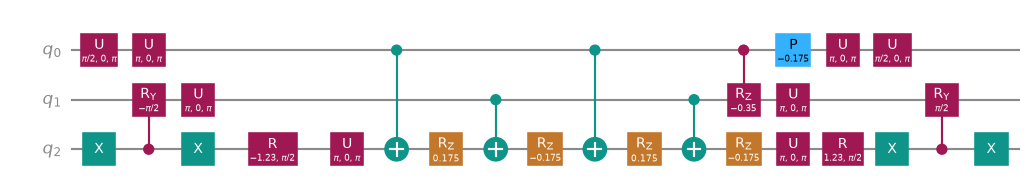

p=2 circuit at random angles: probability outside the 1,296 legal strings = 6.2e-15


In [16]:
def start_state(n):
    qc = QuantumCircuit(3 * n)
    for c in range(n):
        uniform6(qc, 3 * c)
    return qc

for g in (0.3, 2.8):
    ours = start_state(4)
    warmup.cost_layer(ours, H_c, g)
    exact = start_state(4)
    exact.append(PauliEvolutionGate(H_c, time=g), range(12))
    print(f"gamma={g}: fidelity(cost_layer, PauliEvolutionGate) = {state_fidelity(Statevector(ours), Statevector(exact)):.12f}")

one = QuantumCircuit(3)
uniform6(one, 0)
print("uniform6 on one cube, probabilities of codes 0..7:", np.round(Statevector(one).probabilities(), 6))
mix = QuantumCircuit(3)
cube_mixer(mix, 0.7, 0)
show(mix.decompose().draw("mpl", style=CIRCUIT, fold=-1, scale=0.7))

g_rand, b_rand = list(rng.uniform(0, np.pi, 2)), list(rng.uniform(0, np.pi, 2))
p_full = Statevector(compact_qaoa(CUBES, g_rand, b_rand)).probabilities()
leak = 1 - p_full[valid_indices(4)].sum()
print(f"p=2 circuit at random angles: probability outside the 1,296 legal strings = {leak:.1e}")

**What the transpiler does to our circuit.** The judges count two-qubit gates after transpiling to `rz, sx, x, cx`.
`trace_transpile` records, pass by pass, where the circuit size, depth and two-qubit count change (a small version of
a transpiler debugger), here for the p = 1 circuit.

In [17]:
ANGLES = load_angles("results/angles_Cc_N4.json")
qc_p1 = compact_qaoa(CUBES, *angles_for(ANGLES, 1))
traced, trace_rows = trace_transpile(qc_p1, basis_gates=BASIS, seed_transpiler=SEED)
print(f"{'#':>3s}  {'pass':32s} {'size':>6s} {'depth':>6s} {'2q':>6s} {'ms':>8s}")
for row in trace_rows:
    count, name, size, depth, twoq, ms = row
    print(f"{count:3d}  {name:32s} {size:6d} {depth:6d} {twoq:6d} {ms:8.1f}")

  #  pass                               size  depth     2q       ms
  0  ContainsInstruction                  65     10     12      0.0
  2  HighLevelSynthesis                  599    265    384      5.2
  7  InverseCancellation                 595    263    380      0.1
  9  CommutativeCancellation             567    246    352      0.3
 13  HighLevelSynthesis                  591    250    352      0.7
 14  BasisTranslator                     807    287    368      0.6
 15  TwoQubitPeepholeOptimization        778    278    368      0.8
 20  RemoveIdentityEquivalent            762    275    368      0.0
 21  Optimize1qGatesDecomposition        710    269    368      0.3
 22  CommutativeCancellation             698    267    368      0.3


## 8. Choosing the QAOA angles

Each QAOA layer has two angles (gamma for the cost step, beta for the mixer). Because the circuit never leaves the
1,296 legal strings, we can simulate it exactly with a small 1,296-entry vector (`Reduced`, checked against the full
Qiskit statevector in the tests). Below: the p = 1 landscape, a live layer-by-layer training up to p = 3 (each new
layer starts from the previous angles, then L-BFGS-B), and the stored angles up to p = 24 from the same procedure.

**Honesty note.** This training is a classical simulation of all 1,296 cases, which is more work than simply checking
them. We say so plainly. To show the angles are not secretly "the answer", we also run (section 9) angles trained on a
*different* 4-cube puzzle and (section 12) the same angles on larger puzzles they never saw. Row C5 is a 2-number
linear ramp whose two numbers were tuned on this puzzle by a grid search (no layer-by-layer optimisation), so it is a
cheaper schedule, not an unseen-puzzle check.

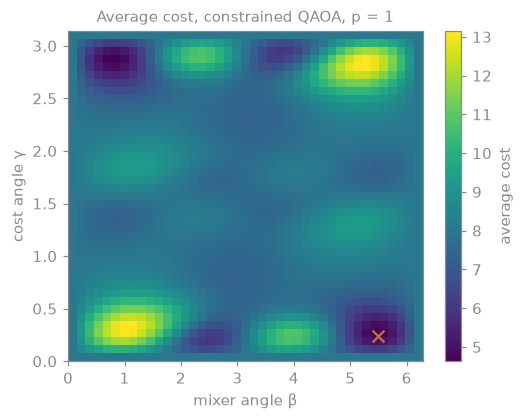

p=1 grid best: gamma=0.236, beta=5.498, E[cost]=4.632, P=0.0113
p=1: E[cost]=4.621  P=0.01096
p=2: E[cost]=3.516  P=0.02738
p=3: E[cost]=3.040  P=0.04773
live training to p=3 took 0.1 s
  p=1: P live 0.0110 | stored 0.0110
  p=2: P live 0.0274 | stored 0.0274
  p=3: P live 0.0477 | stored 0.0477


In [18]:
R4 = Reduced(CUBES)
gs1, bs1 = np.linspace(0, np.pi, 41), np.linspace(0, 2 * np.pi, 41)
E1 = np.array([[R4.energy([g], [b]) for b in bs1] for g in gs1])
i, j = np.unravel_index(E1.argmin(), E1.shape)
plot_landscape(E1, gs1, bs1, (gs1[i], bs1[j]))
print(f"p=1 grid best: gamma={gs1[i]:.3f}, beta={bs1[j]:.3f}, E[cost]={E1[i, j]:.3f}, P={R4.P([gs1[i]], [bs1[j]]):.4f}")

start = time.perf_counter()
live = train_layerwise(CUBES, 3)
print(f"live training to p=3 took {time.perf_counter() - start:.1f} s")
for p in sorted(live):
    print(f"  p={p}: P live {live[p]['P']:.4f} | stored {ANGLES[p]['P']:.4f}")

p= 1: exact P = 0.0110 (stored 0.0110), E[cost] = 4.621
p= 3: exact P = 0.0477 (stored 0.0477), E[cost] = 3.040
p= 6: exact P = 0.2119 (stored 0.2119), E[cost] = 2.074
p=12: exact P = 0.7294 (stored 0.7294), E[cost] = 0.768
p=24: exact P = 0.9854 (stored 0.9854), E[cost] = 0.086


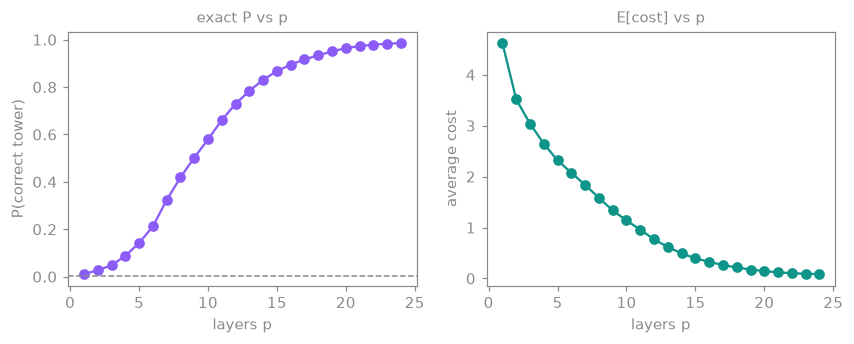

In [19]:
ps = sorted(ANGLES)
P_by_p = {p: R4.P(*angles_for(ANGLES, p)) for p in ps}
E_by_p = {p: R4.energy(*angles_for(ANGLES, p)) for p in ps}
for p in (1, 3, 6, 12, 24):
    if p in P_by_p:
        print(f"p={p:2d}: exact P = {P_by_p[p]:.4f} (stored {ANGLES[p]['P']:.4f}), E[cost] = {E_by_p[p]:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(ps, [P_by_p[p] for p in ps], "o-", color=helpers.VIOLET)
ax[0].axhline(baseline(4, "valid6N"), color=helpers.GREY, ls="--", lw=1)
ax[0].set_xlabel("layers p"); ax[0].set_ylabel("P(correct tower)"); ax[0].set_title("exact P vs p", fontsize=10)
ax[1].plot(ps, [E_by_p[p] for p in ps], "o-", color=helpers.TEAL)
ax[1].set_xlabel("layers p"); ax[1].set_ylabel("average cost"); ax[1].set_title("E[cost] vs p", fontsize=10)
save_show(fig, "angles_vs_p.png")
FACTS["P_by_p"] = {str(p): P_by_p[p] for p in ps}

## 9. Core result 1: QAOA with the legal-move mixer on 12 qubits

Each run below builds the circuit, adds the two-sided marker, transpiles to `rz, sx, x, cx` (seed 7), runs it, and
decodes every shot. A shot counts as a success only if its decoded tower passes `solves(tower_from(...))`; shots that
land on an impossible pattern (110 or 111) are counted separately as `n_invalid`. "Exact" is the probability from the exact simulation,
so you can see the sampled value agrees with it.

| row | angles |
|---|---|
| C0, C1, C2 | trained on this puzzle, p = 3, 12, 24 (C2 is the headline) |
| C3 | trained on a different 4-cube puzzle, `make_puzzle(4, 57)` (fairness check) |
| C4 | p = 3 trained for the best 25 % of shots (CVaR) instead of the average |
| C5 | a 2-number linear ramp, p = 24, tuned on N = 4 by grid search; no layer-by-layer optimisation |

In [20]:
def decode4(key):
    return decode_tower(CUBES, key)


def run_cc(rid, cubes, gammas, betas, algorithm, shots, level="Core", puzzle_name="N=4", H=None, notes=""):
    # build, prepare, run and score one compact-QAOA circuit; return its row
    n = len(cubes)
    H = H if H is not None else compact_hamiltonian(cubes)
    qc = compact_qaoa(cubes, gammas, betas, H=H)
    exact = Reduced(cubes).P(gammas, betas)
    counts = run_on_qbraid(qc, shots=shots, tag=rid, replay=False)
    s = success_rate(counts, lambda key: decode_tower(cubes, key), valid=report.compact_valid)
    towers = {tuple(map(tuple, t)) for t in s["objects"].values()}
    print(f"{rid}: {s['n_good']} of {s['n_total']} shots verified towers, P = {s['P']:.4f} +- {s['se']:.4f}"
          + f" (exact {exact:.4f})"
          + f"; impossible readings {s['n_invalid']}; distinct towers {len(towers)}, all pass solves: "
          + str(all(solves(list(t)) for t in towers)))
    return add_row(make_row(rid, level, puzzle_name, n, "compact, 3 qubits per cube", algorithm, prepared(qc),
                            shots, s, baseline(n, "bits3N"), baseline(n, "valid6N"), p_exact=exact, notes=notes)), counts


row_C0, _ = run_cc("C0", CUBES, *angles_for(ANGLES, 3), "QAOA, legal-move mixer, p=3", SHOTS_N4, H=H_c)
row_C1, _ = run_cc("C1", CUBES, *angles_for(ANGLES, 12), "QAOA, legal-move mixer, p=12", SHOTS_N4, H=H_c)
row_C2, counts_C2 = run_cc("C2", CUBES, *angles_for(ANGLES, 24), "QAOA, legal-move mixer, p=24", SHOTS_N4, H=H_c,
                           notes="headline QAOA row")

No qBraid job was sent, so this ran on the local Aer simulator.


C0: 189 of 4000 shots verified towers, P = 0.0473 +- 0.0034 (exact 0.0477); impossible readings 0; distinct towers 2, all pass solves: True
No qBraid job was sent, so this ran on the local Aer simulator.


C1: 2900 of 4000 shots verified towers, P = 0.7250 +- 0.0071 (exact 0.7294); impossible readings 0; distinct towers 2, all pass solves: True


No qBraid job was sent, so this ran on the local Aer simulator.


C2: 3934 of 4000 shots verified towers, P = 0.9835 +- 0.0020 (exact 0.9854); impossible readings 0; distinct towers 2, all pass solves: True


most frequent C2 result 011001100101 (1973 shots) -> codes [5, 4, 1, 3]


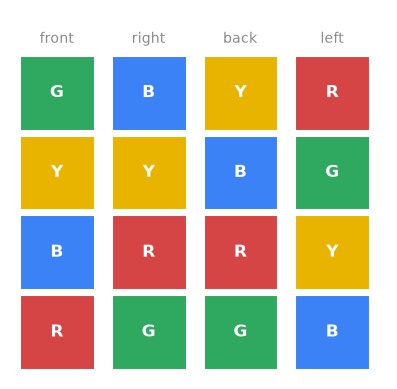

In [21]:
top_key = max(counts_C2, key=counts_C2.get)
print(f"most frequent C2 result {top_key} ({counts_C2[top_key]} shots) -> codes {codes_from_key(top_key, 4)}")
save_drawing(draw_tower, "tower_C2.png", decode_tower(CUBES, top_key))

In [22]:
ANGLES_ALT = load_angles("results/angles_Cc_N4_alt57.json")
row_C3, _ = run_cc("C3", CUBES, *angles_for(ANGLES_ALT, 24), "QAOA p=24, angles trained on make_puzzle(4, 57)",
                   SHOTS_N4, H=H_c, notes="fairness: angles never saw this puzzle")
ANGLES_CVAR = load_angles("results/angles_Cc_N4_cvar.json")
row_C4, _ = run_cc("C4", CUBES, *angles_for(ANGLES_CVAR, 3), "QAOA p=3, CVaR-ladder angles", SHOTS_N4, H=H_c)
RAMP = json.loads(Path("results/ramp_N4.json").read_text())
ramp24 = RAMP["24"]
row_C5, _ = run_cc("C5", CUBES, *ramp_angles(ramp24["dg"], ramp24["db"], 24), "QAOA p=24, 2-parameter linear ramp",
                   SHOTS_N4, H=H_c, notes=f"ramp dg={ramp24['dg']:.3f}, db={ramp24['db']:.3f}")

No qBraid job was sent, so this ran on the local Aer simulator.


C3: 2044 of 4000 shots verified towers, P = 0.5110 +- 0.0079 (exact 0.5208); impossible readings 0; distinct towers 2, all pass solves: True
No qBraid job was sent, so this ran on the local Aer simulator.


C4: 427 of 4000 shots verified towers, P = 0.1067 +- 0.0049 (exact 0.1094); impossible readings 0; distinct towers 2, all pass solves: True
No qBraid job was sent, so this ran on the local Aer simulator.


C5: 1724 of 4000 shots verified towers, P = 0.4310 +- 0.0078 (exact 0.4395); impossible readings 0; distinct towers 2, all pass solves: True


**What this shows.** Trained angles take the success rate from the random-legal-state baseline (0.15 %) to about
98.5 % at p = 24, and every successful shot is a verified tower. Angles trained on another puzzle still reach about
52 %, and a schedule described by only two numbers reaches about 44 %, so most of the effect is the circuit design, not
memorised angles. The price is gates: thousands of CX gates, which is fine on a noiseless simulator like SV1 and far
too many for today's noisy hardware.

## 10. Core result 2: Grover search on the same 12 qubits

Grover search needs an **oracle**: a circuit that flips the sign of exactly the strings that solve the puzzle. Ours is
written only from the rules ("for each side and colour, exactly two chosen lines touch it"), with no knowledge of the
answer; the expression below is generated from the cube list. Grover then repeats "oracle, then reflect about the
start state" K times. Starting from the equal mix of the 1,296 valid placements, with M answers, the success probability
after K rounds is sin^2((2K+1) theta) with sin(theta) = sqrt(M / 1296). With M = 2 the best K is 19.

Grover needs M. We take it from `count_answers` (a classical count); with unknown M one would use the
Boyer-Brassard-Hoyer-Tapp randomised schedule or quantum counting. We say this openly.

In [23]:
expr = oracle_expression(CUBES)
print(f"oracle expression ({len(expr):,} characters), first 200: {expr[:200]} ...")
answer_index = sorted(int(key_from_codes([CHOICES.index(tuple(pc)) for pc in ch]), 2) for ch in answers)
marked = sorted(marked_states(CUBES))
print("states the oracle marks (of all 4,096):", marked, "| answers from the classical check:", answer_index,
      "| equal:", marked == answer_index)
M = count_answers(CUBES)
K_best = grover_iterations(4, M)
print(f"M = {M} answers, best K = {K_best}, predicted P = {grover_success(4, K_best, M):.4f}")

oracle expression (11,725 characters), first 200: ((((~x0 & x1 & ~x2) | (x0 & x1 & ~x2)) & ((~x3 & x4 & ~x5) | (x3 & x4 & ~x5) | (~x3 & ~x4 & x5) | (x3 & ~x4 & x5)) & ~((~x6 & ~x7 & ~x8) | (x6 & ~x7 & ~x8)) & ~((~x9 & ~x10 & x11) | (x9 & ~x10 & x11)) ...


states the oracle marks (of all 4,096): [1637, 2827] | answers from the classical check: [1637, 2827] | equal: True
M = 2 answers, best K = 19, predicted P = 0.9985


No qBraid job was sent, so this ran on the local Aer simulator.


G0 (K=5): 691 of 4000 shots verified towers, P = 0.1727 +- 0.0060 (theory 0.1755); impossible readings 0; qubits 12 data


No qBraid job was sent, so this ran on the local Aer simulator.


G1 (K=10): 2129 of 4000 shots verified towers, P = 0.5323 +- 0.0079 (theory 0.5397); impossible readings 0; qubits 12 data


No qBraid job was sent, so this ran on the local Aer simulator.


G2 (K=19): 3993 of 4000 shots verified towers, P = 0.9982 +- 0.0007 (theory 0.9985); impossible readings 0; qubits 12 data


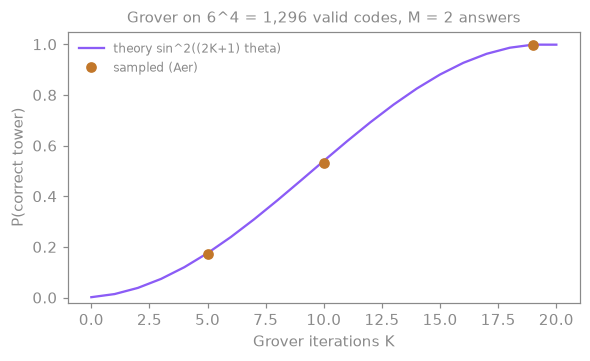

In [24]:
grover_rows = {}
for rid, k in (("G0", 5), ("G1", 10), ("G2", K_best)):
    qc = grover_circuit(CUBES, k)
    counts = run_on_qbraid(qc, shots=SHOTS_N4, tag=rid, replay=False)
    s = success_rate(counts, decode4, valid=report.compact_valid)
    theory = grover_success(4, k, M)
    print(f"{rid} (K={k}): {s['n_good']} of {s['n_total']} shots verified towers, P = {s['P']:.4f} +- {s['se']:.4f}"
          f" (theory {theory:.4f}); impossible readings {s['n_invalid']}; qubits {qc.num_qubits} data")
    grover_rows[k] = add_row(make_row(rid, "Core", "N=4", 4, "compact, 3 qubits per cube",
                                      f"Grover, rules-only oracle, K={k}", prepared(qc), SHOTS_N4, s,
                                      baseline(4, "bits3N"), baseline(4, "valid6N"), p_exact=theory,
                                      qubits_note="12 data + 1 idle ancilla (q0) + 1 marker"))
ks = sorted(grover_rows)
fig = report.plot_grover_curve(ks, lambda k: grover_success(4, k, M), [grover_rows[k]["P"] for k in ks])
save_show(fig, "grover_curve.png")

**Why our Grover circuit is cheap (the clean-ancilla trick).** Each Grover round contains gates controlled by many
qubits. Qiskit builds such a gate much more cheaply if it has one spare qubit that it knows is in state 0. Our
`prepare_safe` adds qubit 0, which is never touched, so the transpiler can use it as that spare in every round. The
oracle alone shows the effect:

In [25]:
oracle = build_oracle(CUBES)
cx_alone = transpile(oracle, basis_gates=BASIS, seed_transpiler=SEED).count_ops().get("cx", 0)
wide = QuantumCircuit(oracle.num_qubits + 1)
wide.compose(oracle, range(1, oracle.num_qubits + 1), inplace=True)
cx_wide = transpile(wide, basis_gates=BASIS, seed_transpiler=SEED).count_ops().get("cx", 0)
print(f"oracle on its 12 qubits: {cx_alone} CX | same oracle with one idle qubit beside it: {cx_wide} CX")
FACTS["oracle_cx"] = {"alone": int(cx_alone), "with_idle": int(cx_wide)}

oracle on its 12 qubits: 880 CX | same oracle with one idle qubit beside it: 117 CX


The trick only works if the idle qubit is never an argument of any gate. If it were passed into the Grover gate it
would be marked "possibly not 0" after the first round and the saving disappears (we measured 14,858 CX instead of
about 4,000 that way during development, and 25,666 CX with no spare qubit at all).

**Equal-cost comparison.** At the same number of CX gates, which method finds the tower more often?

In [26]:
qc_p6 = compact_qaoa(CUBES, *angles_for(ANGLES, 6), H=H_c)
cx_p6 = circuit_metrics(prepared(qc_p6))["cx"]
pairs = [(grover_rows[5], row_C0, None), (grover_rows[10], None, (6, cx_p6)), (grover_rows[K_best], row_C1, None)]
FACTS["equal_cx"] = []
for g_row, c_row, extra in pairs:
    if c_row is not None:
        c_txt, c_cx, c_p = c_row["algorithm"], c_row["cx"], c_row["P_exact"]
    else:
        c_txt, c_cx, c_p = f"QAOA p={extra[0]}", extra[1], P_by_p[extra[0]]
    print(f"{g_row['algorithm']:38s} {g_row['cx']:6d} CX, P {g_row['P_exact']:.4f}   vs   {c_txt:30s} {c_cx:6d} CX, P {c_p:.4f}")
    FACTS["equal_cx"].append({"grover": g_row["algorithm"], "grover_cx": g_row["cx"], "grover_P": g_row["P_exact"],
                              "qaoa": c_txt, "qaoa_cx": c_cx, "qaoa_P": c_p})
print(f"QAOA needs {row_C2['cx']} CX for P {row_C2['P_exact']:.4f} (p=24)")

Grover, rules-only oracle, K=5           1061 CX, P 0.1755   vs   QAOA, legal-move mixer, p=3      1088 CX, P 0.0477
Grover, rules-only oracle, K=10          2106 CX, P 0.5397   vs   QAOA p=6                         2168 CX, P 0.2119
Grover, rules-only oracle, K=19          3987 CX, P 0.9985   vs   QAOA, legal-move mixer, p=12     4328 CX, P 0.7294
QAOA needs 8648 CX for P 0.9854 (p=24)


At 4 cubes Grover wins: higher success for fewer gates. But it needs the number of answers M, and the number of rounds
grows like 6^(N/2) with the number of cubes (section 12). QAOA needs trained angles, but the same angles keep working
on bigger puzzles. That is why we keep both.

## 11. Why we left the starter's 24-qubit encoding

For comparison we run the starter's encoding as a full tower search: 6 qubits per cube (24 in total), W states on both
triples of each cube, the starter's cost, XY mixers, p = 3 with trained angles. It works, but only reaches about 5 %
(the random-legal baseline there is 0.03 %), and it needs twice the qubits.

In [27]:
ANGLES_B = load_angles("results/angles_B_N4.json")
gB, bB = angles_for(ANGLES_B, 3)
qc_B = onehot_qaoa(CUBES, gB, bB)
sim_sv = qiskit_aer.AerSimulator(method="statevector")    # 24 qubits: Aer is much faster than Statevector here
qc_sv = transpile(qc_B, sim_sv, seed_transpiler=SEED)
qc_sv.save_statevector()
probs_B = np.abs(np.asarray(sim_sv.run(qc_sv).result().get_statevector())) ** 2
good_B = sum(probs_B[int(k, 2)] for k in KNOWN)
counts_B = run_on_qbraid(qc_B, shots=SHOTS_N4, tag="B1", replay=False)
def decode_B(key):
    ch = decode_onehot(key, 4)
    return ch if ch is not None and verify_choice(CUBES, ch) else None


s_B = success_rate(counts_B, decode_B, valid=report.onehot_valid)
print(f"B1: {s_B['n_good']} of {s_B['n_total']} shots verified towers, P = {s_B['P']:.4f} +- {s_B['se']:.4f}"
      f" (exact {good_B:.4f}); rejected shots (not one-hot, or both axes picked the same pair): {s_B['n_invalid']}")
row_B1 = add_row(make_row("B1", "Core", "N=4", 4, "starter one-hot, 6 qubits per cube", "QAOA, W x W start + XY mixer, p=3",
                          prepared(qc_B), SHOTS_N4, s_B, baseline(4, "bits6N"), baseline(4, "WxW"), p_exact=good_B))

No qBraid job was sent, so this ran on the local Aer simulator.


B1: 219 of 4000 shots verified towers, P = 0.0548 +- 0.0036 (exact 0.0518); rejected shots (not one-hot, or both axes picked the same pair): 997


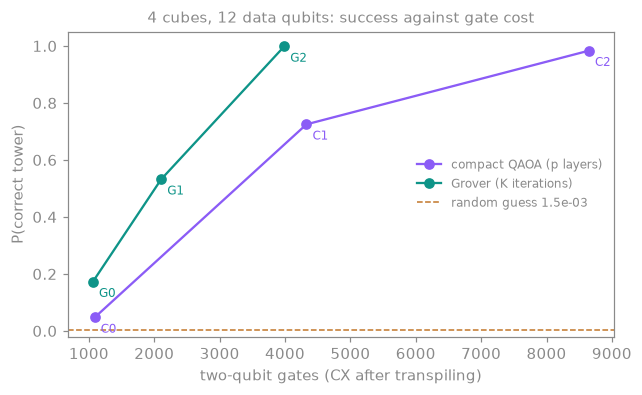

In [28]:
cc_rows = [r for r in ROWS if r["id"] in ("C0", "C1", "C2")]
gr_rows = [grover_rows[k] for k in sorted(grover_rows)]
fig = report.plot_p_sweep(cc_rows, gr_rows, baseline(4, "valid6N"))
save_show(fig, "p_sweep_N4.png")

## 12. Bonus: N cubes and N colours

`make_puzzle(n, seed)` builds a puzzle with N cubes and N colours and one planted tower. We use the seeds the challenge
lists (`{5: 16, 6: 86, 7: 68, 8: 4}`), and check with `count_answers` that each has exactly 2 graph-level answers (one
tower and its quarter turn). The compact encoding uses 3N qubits; the Hamiltonian check is repeated at N = 5 and 6.

We then run the **same p = 24 angles trained at N = 4** on the bigger puzzles, without any new training. "Transfer"
means exactly this: angles from a small puzzle reused on a larger one.

In [29]:
FACTS["bonus"] = {}
for n in (5, 6, 7, 8):
    cubes = instance(n)
    start = time.perf_counter()
    found = count_answers(cubes)
    print(f"N={n} (seed {BONUS[n]}): {cubes} | {6 ** n:,} cases, {found} solve it ({time.perf_counter() - start:.1f} s),"
          f" compact qubits {3 * n}")
    FACTS["bonus"][str(n)] = {"seed": BONUS[n], "answers": found, "qubits": 3 * n}
for n in (5, 6):
    print(f"check_hamiltonian N={n}:", check_hamiltonian(instance(n)))

N=5 (seed 16): [['BE', 'EC', 'DA'], ['AC', 'CE', 'BC'], ['CD', 'BE', 'DE'], ['CD', 'DB', 'EA'], ['EA', 'BD', 'DA']] | 7,776 cases, 2 solve it (0.0 s), compact qubits 15
N=6 (seed 86): [['BD', 'EA', 'BF'], ['CE', 'DC', 'EA'], ['EC', 'CB', 'FD'], ['FE', 'DA', 'DC'], ['BD', 'FB', 'EF'], ['DC', 'BA', 'EC']] | 46,656 cases, 2 solve it (0.1 s), compact qubits 18


N=7 (seed 68): [['AE', 'FD', 'GB'], ['DE', 'EF', 'FC'], ['AB', 'GC', 'DG'], ['FG', 'GC', 'BF'], ['BG', 'EB', 'CF'], ['AE', 'AF', 'FD'], ['EG', 'BD', 'AC']] | 279,936 cases, 2 solve it (0.4 s), compact qubits 21


N=8 (seed 4): [['FB', 'EG', 'GF'], ['EA', 'AC', 'DH'], ['BG', 'AC', 'ED'], ['CF', 'EF', 'BD'], ['BA', 'AH', 'GF'], ['FD', 'EF', 'BF'], ['BG', 'HE', 'EF'], ['DE', 'CD', 'CH']] | 1,679,616 cases, 2 solve it (2.4 s), compact qubits 24
check_hamiltonian N=5: {'n_qubits': 15, 'n_terms': 250, 'max_locality': 4, 'max_gap_valid': 0.0, 'zeros_valid': 2, 'min_nonzero': 2.0, 'zeros_all': 2, 'min_invalid': 4.0}


check_hamiltonian N=6: {'n_qubits': 18, 'n_terms': 361, 'max_locality': 4, 'max_gap_valid': 0.0, 'zeros_valid': 2, 'min_nonzero': 2.0, 'zeros_all': 2, 'min_invalid': 4.0}


In [30]:
start = time.perf_counter()
T1 = transfer_table(ANGLES)
print(f"exact P with the N=4 angles, no retraining ({time.perf_counter() - start:.0f} s):")
print("   N | " + " | ".join(f"p={p:2d}" for p in (8, 16, 24)) + " | random valid placements")
for n in sorted(T1):
    print(f"   {n} | " + " | ".join(f"{T1[n][p]:.3f}" for p in (8, 16, 24)) + f" | {baseline(n, 'valid6N'):.1e}")
FACTS["transfer"] = {str(n): {str(p): v for p, v in T1[n].items()} for n in T1}
ramp_tr = {n: Reduced(instance(n)).P(*ramp_angles(ramp24["dg"], ramp24["db"], 24)) for n in (5, 6, 7, 8)}
print("2-parameter ramp p=24 on N=5..8:", {n: round(v, 3) for n, v in ramp_tr.items()})

exact P with the N=4 angles, no retraining (9 s):
   N | p= 8 | p=16 | p=24 | random valid placements
   3 | 0.621 | 0.765 | 0.890 | 9.3e-03
   4 | 0.419 | 0.894 | 0.985 | 1.5e-03
   5 | 0.105 | 0.298 | 0.479 | 2.6e-04
   6 | 0.101 | 0.286 | 0.369 | 4.3e-05
   7 | 0.045 | 0.131 | 0.171 | 7.1e-06
   8 | 0.045 | 0.182 | 0.284 | 1.2e-06


2-parameter ramp p=24 on N=5..8: {5: 0.119, 6: 0.127, 7: 0.061, 8: 0.096}


In [31]:
angles24 = angles_for(ANGLES, 24)
row_N5, _ = run_cc("N5", instance(5), *angles24, "QAOA p=24, N=4 angles (no retraining)", SHOTS_BONUS,
                   level="Bonus", puzzle_name=f"N=5, make_puzzle(5, {BONUS[5]})")

No qBraid job was sent, so this ran on the local Aer simulator.


N5: 969 of 2000 shots verified towers, P = 0.4845 +- 0.0112 (exact 0.4787); impossible readings 0; distinct towers 2, all pass solves: True


**N = 6, 7, 8.** These circuits have 20 to 26 qubits and tens of thousands of CX gates, so sampling them takes about
15 minutes. With `RUN_HEAVY = False` we load the rows that `scripts/run_heavy.py` produced (same functions, same seed)
and print where they came from; the exact P of each is recomputed live just below so the sampled numbers can be
checked on the spot.

In [32]:
HEAVY = Path("results/heavy_rows.json")
heavy_rows = []
if RUN_HEAVY:
    for n in (6, 7, 8):
        r, _ = run_cc(f"N{n}", instance(n), *angles24, "QAOA p=24, N=4 angles (no retraining)", SHOTS_BONUS,
                      level="Bonus", puzzle_name=f"N={n}, make_puzzle({n}, {BONUS[n]})")
        ROWS.remove(r)
        heavy_rows.append(r)
elif HEAVY.exists():
    heavy = json.loads(HEAVY.read_text())
    print("provenance of results/heavy_rows.json:")
    for key, value in heavy["provenance"].items():
        print(f"  {key}: {value}")
    heavy_rows = heavy["rows"]
else:
    print("results/heavy_rows.json not found: N = 6, 7, 8 are reported below as exact-P values only (no shots).")

for r in heavy_rows:
    n = int(r["N"])
    exact = Reduced(instance(n)).P(*angles24)
    r["P_exact"] = exact
    print(f"{r['id']}: sampled P = {r['P']:.4f} +- {r['P_se']:.4f} from {r['shots']} shots | exact P (recomputed now) {exact:.4f}"
          f" | qubits {r['qubits']}, CX {r['cx']}, depth {r['depth']}")
    add_row(r)
for n in (6, 7, 8):
    if n not in {int(r["N"]) for r in heavy_rows}:
        print(f"N{n}: no sampled row available; exact P with the N=4 angles = {T1[n][24]:.4f} (from the table above)")

provenance of results/heavy_rows.json:
  command: python scripts/run_heavy.py
  seed: 7
  shots: 2000
  qiskit: 2.6.0
  qiskit_aer: 0.17.2
  python: 3.12.15
  machine: x86_64
  timestamp: 2026-10-17T16:11:41+00:00
  wall_s: {'N6': 123.1, 'N7': 341.9, 'N8': 947.1}
  angles: results/angles_Cc_N4.json, p = 24
  device: local AerSimulator (qiskit-aer 0.17.2, seed 7)
N6: sampled P = 0.3590 +- 0.0107 from 2000 shots | exact P (recomputed now) 0.3690 | qubits 20, CX 22476, depth 14001


N7: sampled P = 0.1585 +- 0.0082 from 2000 shots | exact P (recomputed now) 0.1710 | qubits 23, CX 28142, depth 16032


N8: sampled P = 0.2830 +- 0.0101 from 2000 shots | exact P (recomputed now) 0.2841 | qubits 26, CX 38752, depth 24245


In [33]:
print("Grover beyond 4 cubes (estimate from the measured N=4 cost per round, NOT run):")
GB = resource_estimate()
for r in GB:
    print("  ", r)
FACTS["grover_estimate"] = GB

Grover beyond 4 cubes (estimate from the measured N=4 cost per round, NOT run):
   {'N': 5, 'K': 48, 'P_theory': 0.9997722666849005, 'qubits': 17, 'cx_per_iter': 261, 'cx_estimate': 12540, 'label': 'estimate, not run'}
   {'N': 6, 'K': 119, 'P_theory': 0.9999641918213847, 'qubits': 20, 'cx_per_iter': 314, 'cx_estimate': 37306, 'label': 'estimate, not run'}
   {'N': 7, 'K': 293, 'P_theory': 0.9999967900165726, 'qubits': 23, 'cx_per_iter': 366, 'cx_estimate': 107165, 'label': 'estimate, not run'}
   {'N': 8, 'K': 719, 'P_theory': 0.9999997096658195, 'qubits': 26, 'cx_per_iter': 418, 'cx_estimate': 300542, 'label': 'estimate, not run'}


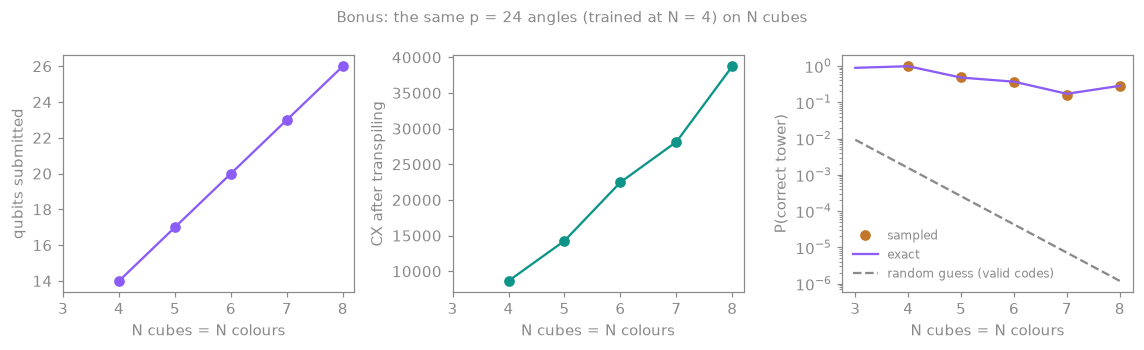

N=4: qubits 14 (12 data), CX 8648, CX per layer about 360, P 0.984 vs random valid placements 1.5e-03
N=5: qubits 17 (15 data), CX 14266, CX per layer about 594, P 0.484 vs random valid placements 2.6e-04
N=6: qubits 20 (18 data), CX 22476, CX per layer about 936, P 0.359 vs random valid placements 4.3e-05
N=7: qubits 23 (21 data), CX 28142, CX per layer about 1173, P 0.159 vs random valid placements 7.1e-06
N=8: qubits 26 (24 data), CX 38752, CX per layer about 1615, P 0.283 vs random valid placements 1.2e-06


In [34]:
bonus_rows = {4: row_C2, 5: row_N5}
bonus_rows.update({int(r["N"]): r for r in heavy_rows})
exact_by_n = {n: T1[n][24] for n in T1}
baselines_by_n = {n: baseline(n, "valid6N") for n in T1}
fig = report.plot_bonus_scaling(bonus_rows, exact_by_n, baselines_by_n)
save_show(fig, "bonus_scaling.png")
for n, r in sorted(bonus_rows.items()):
    print(f"N={n}: qubits {r['qubits']} ({3 * n} data), CX {r['cx']}, CX per layer about {r['cx'] / 24:.0f},"
          f" P {r['P']:.3f} vs random valid placements {baseline(n, 'valid6N'):.1e}")

**How it scales.** Qubits grow as 3N. The cost step has more terms as N grows, so the CX count per layer grows roughly
like 25 N^2. The exact success rate with the N = 4 angles drops from 98.5 % to between about 17 % and 48 %, but it stays
thousands to hundreds of thousands of times above random guessing, without any retraining. Grover would need about
6^(N/2) rounds (48, 119, 293, 719 for N = 5..8); its oracle synthesis already takes minutes at N = 5, so for N >= 6 we
only give an estimate.

## 13. The same circuits on qBraid SV1

Four rows were run once on qBraid's SV1 state-vector simulator (`aws:aws:sim:sv1`) by `scripts/run_sv1.py`: the
headline QAOA row C2, the headline Grover row G2, the warm-up W1 and the Bonus row N5. Here we rebuild each circuit
exactly as above and replay the saved counts from `results/sv1_counts/<tag>.json`. A file is used only if the SHA-256
fingerprint of the transpiled circuit, the device and the shot count all match; otherwise the row is left out (never
filled with a local run). Nothing is sent to qBraid. Every SV1 shot goes through the same decoders and `solves` checks
as the local rows. SV1, like the local Aer simulator, is noiseless, so the two should agree within sampling error.

In [35]:
def insert_after(parent_id, row):
    # put a row right after the row it repeats, so the table reads local, SV1, hardware side by side
    ids = [r["id"] for r in ROWS]
    pos = max(i for i, rid in enumerate(ids) if rid == parent_id or rid.startswith(parent_id + "-"))
    ROWS.insert(pos + 1, row)
    return row


cubes5 = instance(5)
SV1_SPECS = [   # tag, circuit rebuilt with the same code as the local row, shots, decoder, legality test
    ("W1", w1_circuit, SHOTS_N4, good_pick, report.frontback_valid),
    ("C2", compact_qaoa(CUBES, *angles_for(ANGLES, 24), H=H_c), SHOTS_N4, decode4, report.compact_valid),
    ("G2", grover_circuit(CUBES, K_best), SHOTS_N4, decode4, report.compact_valid),
    ("N5", compact_qaoa(cubes5, *angles24), SHOTS_BONUS, lambda key: decode_tower(cubes5, key), report.compact_valid),
]
sv1_rows = {}
LOCAL = {r["id"]: r for r in ROWS}
for tag, qc, shots, decoder, valid in (SV1_SPECS if REPLAY_SV1 else []):
    counts = runtime.replay_sv1(qc, shots, tag)
    if counts is None:
        continue
    s = success_rate(counts, decoder, valid=valid)
    loc = LOCAL[tag]
    row = make_row(f"{tag}-SV1", loc["level"], loc["puzzle"], loc["N"], loc["encoding"], loc["algorithm"],
                   prepared(qc), shots, s, loc["baseline_bits"], loc["baseline_subspace"], p_exact=loc["P_exact"],
                   notes=f"qBraid SV1, counts replayed from results/sv1_counts/{tag}.json",
                   qubits_note=loc["qubits_note"])
    assert (row["qubits"], row["cx"], row["depth"]) == (loc["qubits"], loc["cx"], loc["depth"]), "not the same circuit"
    if tag == "W1":
        checked = all(is_two_factor(CUBES, picks) for picks in s["objects"].values())
    else:
        checked = all(solves(t) for t in s["objects"].values())
    z = (s["P"] - loc["P_exact"]) / np.sqrt(loc["P_exact"] * (1 - loc["P_exact"]) / shots)   # se under the exact P
    print(f"{tag}-SV1: {s['n_good']} of {s['n_total']} shots verified, P = {s['P']:.4f} +- {s['se']:.4f}"
          f" | local Aer {loc['P']:.4f} +- {loc['P_se']:.4f} | exact {loc['P_exact']:.4f} ({z:+.1f} standard errors)"
          f" | impossible readings {s['n_invalid']} | every success re-checked: {checked} | job {row['job_id']}")
    assert checked
    sv1_rows[tag] = insert_after(tag, row)
runtime.LAST_RUN.update(source=None, device=None, job_id="", credits=None)
FACTS["sv1"] = {tag: {"P": r["P"], "se": r["P_se"], "P_exact": r["P_exact"], "job_id": r["job_id"],
                      "credits": r["credits"]} for tag, r in sv1_rows.items()}
print(f"{len(sv1_rows)} SV1 rows added; no job was submitted from this notebook")

replaying SV1 counts for W1, job aws:aws:sim:sv1-5a53-qjob-6ad3adc738127b44c71ba019 (no new job, no credits)
W1-SV1: 1204 of 4000 shots verified, P = 0.3010 +- 0.0073 | local Aer 0.2807 +- 0.0071 | exact 0.2840 (+2.4 standard errors) | impossible readings 0 | every success re-checked: True | job aws:aws:sim:sv1-5a53-qjob-6ad3adc738127b44c71ba019


replaying SV1 counts for C2, job aws:aws:sim:sv1-5a53-qjob-6ad3ad0838127b44c71b9ff4 (no new job, no credits)
C2-SV1: 3942 of 4000 shots verified, P = 0.9855 +- 0.0019 | local Aer 0.9835 +- 0.0020 | exact 0.9854 (+0.0 standard errors) | impossible readings 0 | every success re-checked: True | job aws:aws:sim:sv1-5a53-qjob-6ad3ad0838127b44c71b9ff4


replaying SV1 counts for G2, job aws:aws:sim:sv1-5a53-qjob-6ad3ad6c38127b44c71ba006 (no new job, no credits)
G2-SV1: 3998 of 4000 shots verified, P = 0.9995 +- 0.0004 | local Aer 0.9982 +- 0.0007 | exact 0.9985 (+1.6 standard errors) | impossible readings 0 | every success re-checked: True | job aws:aws:sim:sv1-5a53-qjob-6ad3ad6c38127b44c71ba006


replaying SV1 counts for N5, job aws:aws:sim:sv1-5a53-qjob-6ad3adf038127b44c71ba022 (no new job, no credits)


N5-SV1: 932 of 2000 shots verified, P = 0.4660 +- 0.0112 | local Aer 0.4845 +- 0.0112 | exact 0.4787 (-1.1 standard errors) | impossible readings 0 | every success re-checked: True | job aws:aws:sim:sv1-5a53-qjob-6ad3adf038127b44c71ba022
4 SV1 rows added; no job was submitted from this notebook


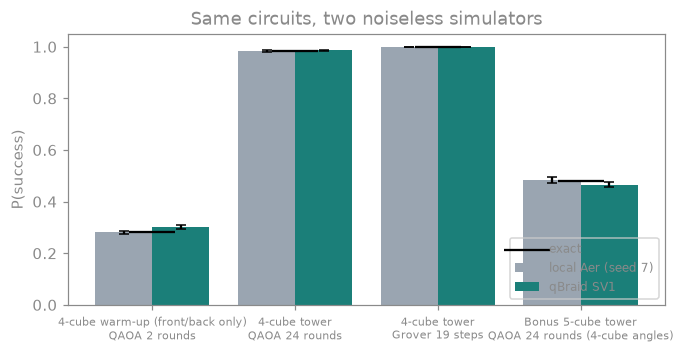

In [36]:
if sv1_rows:
    tags = list(sv1_rows)
    x = np.arange(len(tags))
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.bar(x - 0.2, [LOCAL[t]["P"] for t in tags], 0.4, yerr=[LOCAL[t]["P_se"] for t in tags], color="#9aa5b1",
           label="local Aer (seed 7)", capsize=3)
    ax.bar(x + 0.2, [sv1_rows[t]["P"] for t in tags], 0.4, yerr=[sv1_rows[t]["P_se"] for t in tags], color="#1b7f79",
           label="qBraid SV1", capsize=3)
    ax.scatter(x, [LOCAL[t]["P_exact"] for t in tags], marker="_", s=900, color="black", zorder=3, label="exact")
    ax.set_xticks(x, [report.label_of(sv1_rows[t]).replace(", ", "\n", 1) for t in tags], fontsize=7)
    ax.set_ylabel("P(success)")
    ax.set_ylim(0, 1.05)
    ax.set_title("Same circuits, two noiseless simulators")
    ax.legend(loc="lower right", fontsize=8)
    save_show(fig, "sv1_vs_aer.png")

**What this shows.** SV1 and the local simulator agree with each other and with the exact value within sampling error,
as they should for two noiseless simulators running the same transpiled circuit (W1 is a front/back pick, not a full
tower). The SV1 rows confirm that the submitted circuits are the ones in this notebook and that the decoding survives
a real provider's bit order; they are not evidence of anything a classical simulator cannot do.

## 14. Real hardware (Rigetti Cepheus-1-108Q)

The shallowest circuits (a few hundred CX gates) and, as a check, some deep headline circuits were sent to Rigetti's
Cepheus-1-108Q superconducting QPU
(`rigetti:rigetti:qpu:cepheus-1-108q`) through qBraid by `scripts/run_qpu.py`. Here we only read the saved counts in
`results/qpu_counts/` (no network), check that each saved job ran the circuit rebuilt below (fingerprint in
`results/jobs.json`), and decode every shot with the same decoders. The two marker bits only fix the bit order (by the pattern most shots show); the data bits of
every shot are decoded, no shot is dropped, and how often the markers flipped is printed as a direct noise measure. Each hardware row is compared with the noiseless probability of
the same circuit and with random guessing. "Valid readings" is the share of shots where every cube's 3 bits decode to one of its real placements
(for the tower, the patterns 110 and 111 are impossible); it is 100 % on a perfect machine.

In [37]:
QPU_DEVICE = "rigetti:rigetti:qpu:cepheus-1-108q"
QPU_DIR = Path("results/qpu_counts")
JOB_LOG = json.loads(Path("results/jobs.json").read_text()) if Path("results/jobs.json").exists() else []
QPU_SPECS = {   # tag in run_qpu.py -> circuit rebuilt here, decoder, legality test, N, row id, row it sits next to
    "W1p1": (constrained_qaoa(H_fb, [g1], [b1]), good_pick, report.frontback_valid, 4, "W1p1-QPU", "W1",
             "Warm-up", "N=4 front/back only", "one-hot, 3 qubits per cube (front/back only)",
             "W state + XY mixer QAOA, p=1 (grid optimum)", ("fb_bits", "fb_valid")),
    "G1": (grover_circuit(CUBES, 1), decode4, report.compact_valid, 4, "G1-QPU", "G0", "Core", "N=4",
           "compact, 3 qubits per cube", "Grover, rules-only oracle, K=1", ("bits3N", "valid6N")),
    "Cc1": (compact_qaoa(CUBES, *angles_for(ANGLES, 1)), decode4, report.compact_valid, 4, "Cc1-QPU", "C0", "Core",
            "N=4", "compact, 3 qubits per cube", "QAOA, legal-move mixer, p=1", ("bits3N", "valid6N")),
    "G1N5": (grover_circuit(cubes5, 1), lambda key: decode_tower(cubes5, key), report.compact_valid, 5, "G1N5-QPU",
             "N5", "Bonus", f"N=5, make_puzzle(5, {BONUS[5]})", "compact, 3 qubits per cube",
             "Grover, rules-only oracle, K=1", ("bits3N", "valid6N")),
    # the deep headline circuits, the same objects as the local and SV1 rows
    "C2": (SV1_SPECS[1][1], decode4, report.compact_valid, 4, "C2-QPU", "C2", "Core", "N=4",
           "compact, 3 qubits per cube", "QAOA, legal-move mixer, p=24", ("bits3N", "valid6N")),
    "G2": (SV1_SPECS[2][1], decode4, report.compact_valid, 4, "G2-QPU", "G2", "Core", "N=4",
           "compact, 3 qubits per cube", f"Grover, rules-only oracle, K={K_best}", ("bits3N", "valid6N")),
    "N5": (SV1_SPECS[3][1], lambda key: decode_tower(cubes5, key), report.compact_valid, 5, "N5-QPU", "N5", "Bonus",
           f"N=5, make_puzzle(5, {BONUS[5]})", "compact, 3 qubits per cube", "QAOA p=24, N=4 angles (no retraining)",
           ("bits3N", "valid6N")),
}


def final_job(job_id):
    # the last record of a job in results/jobs.json (the log holds a 'submitted' and a final record)
    recs = [j for j in JOB_LOG if j.get("job_id") == job_id]
    return recs[-1] if recs else None


qpu_rows = {}
for path in sorted(QPU_DIR.glob("*.json")) if QPU_DIR.exists() else []:
    saved = json.loads(path.read_text())
    tag = saved.get("tag")
    if tag not in QPU_SPECS or saved.get("device") != QPU_DEVICE or not saved.get("counts"):
        print(f"{path.name}: skipped (unknown tag, other device or no counts)")
        continue
    core, decoder, valid, n, rid, parent, level, puzzle_name, enc, alg, (bb, bs) = QPU_SPECS[tag]
    qc = prepared(core)
    job = final_job(saved["job_id"])
    if job is None or job.get("fingerprint") != runtime.fingerprint(qc) or job.get("status") != "COMPLETED":
        print(f"{tag}: job {saved['job_id']} not in results/jobs.json as COMPLETED with this circuit; no row")
        continue
    counts, marker = runtime.strip_marker_noisy(saved["counts"])
    s_all = success_rate(counts, decoder, valid=valid)
    n_total = s_all["n_total"]
    assert n_total == saved["shots"], (n_total, saved["shots"])
    p, s = s_all["P"], s_all
    if tag in LOCAL and (LOCAL[tag]["cx"], LOCAL[tag]["depth"]) == (circuit_metrics(qc)["cx"], circuit_metrics(qc)["depth"]):
        p_ideal = LOCAL[tag]["P_exact"]          # same circuit as the local row: reuse its exact value
    else:
        ideal = runtime.exact_distribution(qc)
        p_ideal = sum(v for key, v in ideal.items() if decoder(key))
    if tag == "W1p1":
        checked = all(is_two_factor(CUBES, picks) for picks in s["objects"].values())
    else:
        checked = all(solves(t) for t in s["objects"].values())
    assert checked
    runtime.LAST_RUN.update(source="qpu-replay", device=QPU_DEVICE, job_id=saved["job_id"],
                            credits=job.get("actual") if job.get("actual") is not None else saved.get("cost"))
    row = make_row(rid, level, puzzle_name, n, enc, alg, qc, saved["shots"], s_all, baseline(n, bb), baseline(n, bs),
                   p_exact=p_ideal, notes=f"Rigetti QPU, counts from results/qpu_counts/{path.name}; exact = noiseless")
    legal = 1 - s_all["n_invalid"] / n_total
    other = success_rate({k[::-1]: v for k, v in counts.items()}, decoder)["n_good"]   # the other bit order, as a check
    print(f"{rid}: {s['n_good']} of {n_total} shots verified, P = {p:.4f} +- {s_all['se']:.4f} | noiseless {p_ideal:.4f}"
          f" | random {baseline(n, bs):.2e} (random valid placements) | valid readings {legal:.3f} (perfect machine 1.000,"
          f" uniformly random bits {baseline(n, bb) / baseline(n, bs):.3f})"
          f" | marker flips: top {marker['top_marker_error']:.1%}, q0 {marker['idle_qubit_error']:.1%}"
          f" | successes if the bit order were reversed: {other}"
          f" | {row['cx']} CX, depth {row['depth']} | job {row['job_id']} ({row['credits']:g} credits)")
    above = p - 2 * s_all["se"] > baseline(n, bs)
    print(f"   -> {'clearly above' if above else 'not above'} random valid placements; valid readings "
          f"{'close to' if abs(legal - baseline(n, bb) / baseline(n, bs)) < 0.1 else 'different from'} random bits")
    qpu_rows[tag] = insert_after(parent, row)
runtime.LAST_RUN.update(source=None, device=None, job_id="", credits=None)
FACTS["qpu"] = {tag: {"id": r["id"], "P": r["P"], "se": r["P_se"], "P_noiseless": r["P_exact"],
                      "baseline": r["baseline_subspace"], "job_id": r["job_id"], "credits": r["credits"],
                      "cx": r["cx"], "shots": r["shots"]} for tag, r in qpu_rows.items()}
if not qpu_rows:
    print("no hardware counts saved in results/qpu_counts/: no hardware rows")

G1-QPU: 0 of 500 shots verified, P = 0.0000 +- 0.0000 | noiseless 0.0138 | random 1.54e-03 (random valid placements) | valid readings 0.278 (perfect machine 1.000, uniformly random bits 0.316) | marker flips: top 45.8%, q0 45.0% | successes if the bit order were reversed: 0 | 225 CX, depth 330 | job rigetti:rigetti:qpu:cepheus-1-108q-5a53-qjob-6ad3b05c38127b44c71ba094 (44.7126 credits)
   -> not above random valid placements; valid readings close to random bits


G1N5-QPU: 0 of 500 shots verified, P = 0.0000 +- 0.0000 | noiseless 0.0023 | random 2.57e-04 (random valid placements) | valid readings 0.210 (perfect machine 1.000, uniformly random bits 0.237) | marker flips: top 44.8%, q0 48.0% | successes if the bit order were reversed: 0 | 287 CX, depth 357 | job rigetti:rigetti:qpu:cepheus-1-108q-5a53-qjob-6ad3b1b338127b44c71ba0fc (48.7654 credits)
   -> not above random valid placements; valid readings close to random bits
W1p1-QPU: 0 of 500 shots verified, P = 0.0000 +- 0.0000 | noiseless 0.1878 | random 4.94e-02 (random valid placements) | valid readings 0.020 (perfect machine 1.000, uniformly random bits 0.020) | marker flips: top 38.2%, q0 2.8% | successes if the bit order were reversed: 0 | 166 CX, depth 120 | job rigetti:rigetti:qpu:cepheus-1-108q-5a53-qjob-6ad3ae8a38127b44c71ba037 (42.3102 credits)
   -> not above random valid placements; valid readings close to random bits


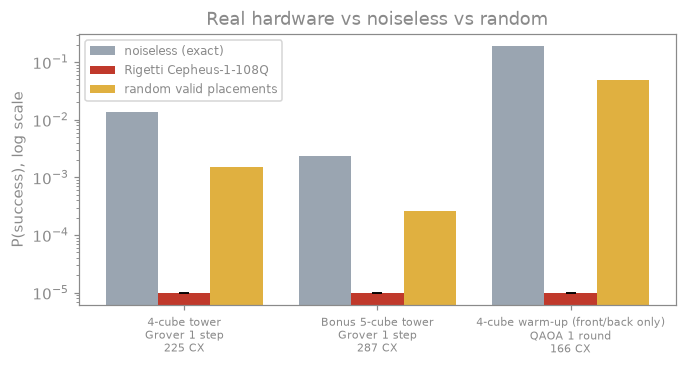

In [38]:
if qpu_rows:
    tags = list(qpu_rows)
    x = np.arange(len(tags))
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.bar(x - 0.27, [qpu_rows[t]["P_exact"] for t in tags], 0.27, color="#9aa5b1", label="noiseless (exact)")
    ax.bar(x, [max(qpu_rows[t]["P"], 1e-5) for t in tags], 0.27, yerr=[qpu_rows[t]["P_se"] for t in tags],
           color="#c0392b", label="Rigetti Cepheus-1-108Q", capsize=3)
    ax.bar(x + 0.27, [qpu_rows[t]["baseline_subspace"] for t in tags], 0.27, color="#e0b040", label="random valid placements")
    ax.set_yscale("log")
    ax.set_xticks(x, [report.label_of(qpu_rows[t]).replace(", ", "\n", 1) + f"\n{qpu_rows[t]['cx']} CX" for t in tags],
                  fontsize=7)
    ax.set_ylabel("P(success), log scale")
    ax.set_title("Real hardware vs noiseless vs random")
    ax.legend(fontsize=8)
    save_show(fig, "qpu_vs_noiseless.png")

**What this shows.** Even the shallowest circuits here have a few hundred CX gates, and on today's hardware each one
adds a little error (and the top marker shows the qubits also decay while they wait), so the hardware success rate
falls far below the noiseless value; the lines above say for each circuit whether anything is left above random
guessing. The valid readings on this QPU are about what uniformly random bits give (instead of 100 %), so the noise
scrambled the state. Deeper circuits only add more error. No
speedup or advantage is claimed from any hardware run.

## 15. Results

**Comparison table.** One line per circuit: the noiseless (exact) success probability, the same circuit on qBraid's
SV1 simulator and on Rigetti's Cepheus-1-108Q QPU where a job exists (blank otherwise), and random guessing.
"Rounds" (QAOA layers) and "steps" (Grover iterations) are the depth of the circuit: more of them means more gates.
A noiseless value is the best the circuit can do even on a perfect machine; for example one QAOA round of the warm-up
(W1p1) reaches only 18.8 % noiseless, the best one QAOA round can do even on a perfect machine, so its hardware
result should be compared with that, not with 100 %.

**GRADING-format table.** One row per experiment, in the columns the challenge asks for. Two-qubit gates and depth
are read from the circuit that was actually run (transpiled to `rz, sx, x, cx` at Qiskit's default level, seed 7).
Qubits include our 2 plumbing qubits (the idle qubit 0 and the marker). P is the fraction of shots whose decoded
answer passed the checks, with its standard error. Both tables are saved under `results/` and pasted from there into
the README.

In [39]:
COMPARISON = report.comparison_table(ROWS)
display(Markdown(COMPARISON))
TABLE = results_table(ROWS)
display(Markdown(TABLE))
Path("results/results_table_all.md").write_text(TABLE + "\n")              # every row
Path("results/comparison_table.md").write_text(report.comparison_table(report.readme_rows(ROWS)) + "\n")
Path("results/results_table.md").write_text(results_table(report.readme_rows(ROWS)) + "\n")   # README subset
save_results(ROWS, "results/results.json")
FACTS["generated"] = time.strftime("%Y-%m-%d %H:%M %Z")
FACTS["versions"] = {"qiskit": qiskit.__version__, "qiskit_aer": qiskit_aer.__version__}
Path("results/facts.json").write_text(json.dumps(FACTS, indent=1, default=float))
print(f"{len(ROWS)} rows saved to results/results.json")
jobs = Path("results/jobs.json")
print("qBraid jobs so far (results/jobs.json):", jobs.read_text().strip() if jobs.exists() else "[] (file missing)")

| Experiment | Two-qubit gates | Perfect simulator | qBraid SV1 | Rigetti QPU | Random valid placements | Any 12-bit string |
|---|---|---|---|---|---|---|
| 4-cube warm-up (front/back only), QAOA 2 rounds (W1, W1-SV1) | 300 | 28.4 % | 30.1 +- 0.7 % |  | 4.9 % | 0.098 % |
| 4-cube warm-up (front/back only), QAOA 1 round (W1p1-QPU) | 166 | 18.8 % |  | 0.0 +- 0.0 % (0/500); valid readings 2.0 % | 4.9 % | 0.098 % |
| 4-cube tower, QAOA 3 rounds (C0) | 1,088 | 4.8 % |  |  | 0.15 % | 0.049 % |
| 4-cube tower, QAOA 12 rounds (C1) | 4,328 | 72.9 % |  |  | 0.15 % | 0.049 % |
| 4-cube tower, QAOA 24 rounds (C2, C2-SV1) | 8,648 | 98.5 % | 98.6 +- 0.2 % |  | 0.15 % | 0.049 % |
| 4-cube tower, QAOA 24 rounds, angles from another puzzle (C3) | 8,648 | 52.1 % |  |  | 0.15 % | 0.049 % |
| 4-cube tower, QAOA 3 rounds, CVaR-trained angles (C4) | 1,088 | 10.9 % |  |  | 0.15 % | 0.049 % |
| 4-cube tower, QAOA 24 rounds, 2-number ramp (tuned on N=4) (C5) | 8,648 | 43.9 % |  |  | 0.15 % | 0.049 % |
| 4-cube tower, Grover 5 steps (G0) | 1,061 | 17.5 % |  |  | 0.15 % | 0.049 % |
| 4-cube tower, Grover 1 step (G1-QPU) | 225 | 1.4 % |  | 0.0 +- 0.0 % (0/500); valid readings 27.8 % | 0.15 % | 0.049 % |
| 4-cube tower, Grover 10 steps (G1) | 2,106 | 54.0 % |  |  | 0.15 % | 0.049 % |
| 4-cube tower, Grover 19 steps (G2, G2-SV1) | 3,987 | 99.85 % | 99.95 +- 0.04 % |  | 0.15 % | 0.049 % |
| 4-cube tower, starter 24-qubit encoding, QAOA 3 rounds (B1) | 940 | 5.2 % |  |  | 0.03 % | 1.2e-05 % (24-bit) |
| Bonus 5-cube tower, QAOA 24 rounds (4-cube angles) (N5, N5-SV1) | 14,266 | 47.9 % | 46.6 +- 1.1 % |  | 0.026 % | 0.0061 % (15-bit) |
| Bonus 5-cube tower, Grover 1 step (G1N5-QPU) | 287 | 0.23 % |  | 0.0 +- 0.0 % (0/500); valid readings 21.0 % | 0.026 % | 0.0061 % (15-bit) |
| Bonus 6-cube tower, QAOA 24 rounds (4-cube angles) (N6) | 22,476 | 36.9 % |  |  | 0.0043 % | 0.00076 % (18-bit) |
| Bonus 7-cube tower, QAOA 24 rounds (4-cube angles) (N7) | 28,142 | 17.1 % |  |  | 0.00071 % | 9.5e-05 % (21-bit) |
| Bonus 8-cube tower, QAOA 24 rounds (4-cube angles) (N8) | 38,752 | 28.4 % |  |  | 0.00012 % | 1.2e-05 % (24-bit) |

| Puzzle (N cubes) | Encoding | Device | Qubits | Two-qubit gates (after transpiling) | Depth | Shots | P(correct tower) | Random-guess baseline | qBraid job ID |
|---|---|---|---|---|---|---|---|---|---|
| 4-cube warm-up (front/back only), QAOA 2 rounds (W1): N=4 front/back only | one-hot, 3 qubits per cube (front/back only), W state + XY mixer QAOA, p=2 (COBYLA) | local AerSimulator (qiskit-aer 0.17.2, seed 7) | 14 (12 data + 2 plumbing) | 300 | 221 | 4,000 | 0.2807 +- 0.0071 (exact 0.2840) | 9.77e-04 (any 12-bit string) / 4.94e-02 (random valid placements) | none (local run) |
| 4-cube warm-up (front/back only), QAOA 2 rounds (W1-SV1): N=4 front/back only | one-hot, 3 qubits per cube (front/back only), W state + XY mixer QAOA, p=2 (COBYLA) | aws:aws:sim:sv1 | 14 (12 data + 2 plumbing) | 300 | 221 | 4,000 | 0.3010 +- 0.0073 (exact 0.2840) | 9.77e-04 (any 12-bit string) / 4.94e-02 (random valid placements) | aws:aws:sim:sv1-5a53-qjob-6ad3adc738127b44c71ba019 (0.375 credits) |
| 4-cube warm-up (front/back only), QAOA 1 round (W1p1-QPU): N=4 front/back only | one-hot, 3 qubits per cube (front/back only), W state + XY mixer QAOA, p=1 (grid optimum) | rigetti:rigetti:qpu:cepheus-1-108q | 14 (12 data + 2 plumbing) | 166 | 120 | 500 | 0.0000 +- 0.0000 (exact 0.1878) | 9.77e-04 (any 12-bit string) / 4.94e-02 (random valid placements) | rigetti:rigetti:qpu:cepheus-1-108q-5a53-qjob-6ad3ae8a38127b44c71ba037 (42.3102 credits) |
| 4-cube tower, QAOA 3 rounds (C0): N=4 | compact, 3 qubits per cube, QAOA, legal-move mixer, p=3 | local AerSimulator (qiskit-aer 0.17.2, seed 7) | 14 (12 data + 2 plumbing) | 1,088 | 782 | 4,000 | 0.0473 +- 0.0034 (exact 0.0477) | 4.88e-04 (any 12-bit string) / 1.54e-03 (random valid placements) | none (local run) |
| 4-cube tower, QAOA 12 rounds (C1): N=4 | compact, 3 qubits per cube, QAOA, legal-move mixer, p=12 | local AerSimulator (qiskit-aer 0.17.2, seed 7) | 14 (12 data + 2 plumbing) | 4,328 | 3,095 | 4,000 | 0.7250 +- 0.0071 (exact 0.7294) | 4.88e-04 (any 12-bit string) / 1.54e-03 (random valid placements) | none (local run) |
| 4-cube tower, QAOA 24 rounds (C2): N=4 | compact, 3 qubits per cube, QAOA, legal-move mixer, p=24 | local AerSimulator (qiskit-aer 0.17.2, seed 7) | 14 (12 data + 2 plumbing) | 8,648 | 6,179 | 4,000 | 0.9835 +- 0.0020 (exact 0.9854) | 4.88e-04 (any 12-bit string) / 1.54e-03 (random valid placements) | none (local run) |
| 4-cube tower, QAOA 24 rounds (C2-SV1): N=4 | compact, 3 qubits per cube, QAOA, legal-move mixer, p=24 | aws:aws:sim:sv1 | 14 (12 data + 2 plumbing) | 8,648 | 6,179 | 4,000 | 0.9855 +- 0.0019 (exact 0.9854) | 4.88e-04 (any 12-bit string) / 1.54e-03 (random valid placements) | aws:aws:sim:sv1-5a53-qjob-6ad3ad0838127b44c71b9ff4 (0.375 credits) |
| 4-cube tower, QAOA 24 rounds, angles from another puzzle (C3): N=4 | compact, 3 qubits per cube, QAOA p=24, angles trained on make_puzzle(4, 57) | local AerSimulator (qiskit-aer 0.17.2, seed 7) | 14 (12 data + 2 plumbing) | 8,648 | 6,179 | 4,000 | 0.5110 +- 0.0079 (exact 0.5208) | 4.88e-04 (any 12-bit string) / 1.54e-03 (random valid placements) | none (local run) |
| 4-cube tower, QAOA 3 rounds, CVaR-trained angles (C4): N=4 | compact, 3 qubits per cube, QAOA p=3, CVaR-ladder angles | local AerSimulator (qiskit-aer 0.17.2, seed 7) | 14 (12 data + 2 plumbing) | 1,088 | 782 | 4,000 | 0.1067 +- 0.0049 (exact 0.1094) | 4.88e-04 (any 12-bit string) / 1.54e-03 (random valid placements) | none (local run) |
| 4-cube tower, QAOA 24 rounds, 2-number ramp (tuned on N=4) (C5): N=4 | compact, 3 qubits per cube, QAOA p=24, 2-parameter linear ramp | local AerSimulator (qiskit-aer 0.17.2, seed 7) | 14 (12 data + 2 plumbing) | 8,648 | 6,202 | 4,000 | 0.4310 +- 0.0078 (exact 0.4395) | 4.88e-04 (any 12-bit string) / 1.54e-03 (random valid placements) | none (local run) |
| 4-cube tower, Grover 5 steps (G0): N=4 | compact, 3 qubits per cube, Grover, rules-only oracle, K=5 | local AerSimulator (qiskit-aer 0.17.2, seed 7) | 14 (12 data + 1 idle ancilla (q0) + 1 marker) | 1,061 | 1,550 | 4,000 | 0.1727 +- 0.0060 (exact 0.1755) | 4.88e-04 (any 12-bit string) / 1.54e-03 (random valid placements) | none (local run) |
| 4-cube tower, Grover 1 step (G1-QPU): N=4 | compact, 3 qubits per cube, Grover, rules-only oracle, K=1 | rigetti:rigetti:qpu:cepheus-1-108q | 14 (12 data + 2 plumbing) | 225 | 330 | 500 | 0.0000 +- 0.0000 (exact 0.0138) | 4.88e-04 (any 12-bit string) / 1.54e-03 (random valid placements) | rigetti:rigetti:qpu:cepheus-1-108q-5a53-qjob-6ad3b05c38127b44c71ba094 (44.7126 credits) |
| 4-cube tower, Grover 10 steps (G1): N=4 | compact, 3 qubits per cube, Grover, rules-only oracle, K=10 | local AerSimulator (qiskit-aer 0.17.2, seed 7) | 14 (12 data + 1 idle ancilla (q0) + 1 marker) | 2,106 | 3,075 | 4,000 | 0.5323 +- 0.0079 (exact 0.5397) | 4.88e-04 (any 12-bit string) / 1.54e-03 (random valid placements) | none (local run) |
| 4-cube tower, Grover 19 steps (G2): N=4 | compact, 3 qubits per cube, Grover, rules-only oracle, K=19 | local AerSimulator (qiskit-aer 0.17.2, seed 7) | 14 (12 data + 1 idle ancilla (q0) + 1 marker) | 3,987 | 5,820 | 4,000 | 0.9982 +- 0.0007 (exact 0.9985) | 4.88e-04 (any 12-bit string) / 1.54e-03 (random valid placements) | none (local run) |
| 4-cube tower, Grover 19 steps (G2-SV1): N=4 | compact, 3 qubits per cube, Grover, rules-only oracle, K=19 | aws:aws:sim:sv1 | 14 (12 data + 1 idle ancilla (q0) + 1 marker) | 3,987 | 5,820 | 4,000 | 0.9995 +- 0.0004 (exact 0.9985) | 4.88e-04 (any 12-bit string) / 1.54e-03 (random valid placements) | aws:aws:sim:sv1-5a53-qjob-6ad3ad6c38127b44c71ba006 (0.375 credits) |
| 4-cube tower, starter 24-qubit encoding, QAOA 3 rounds (B1): N=4 | starter one-hot, 6 qubits per cube, QAOA, W x W start + XY mixer, p=3 | local AerSimulator (qiskit-aer 0.17.2, seed 7) | 26 (24 data + 2 plumbing) | 940 | 318 | 4,000 | 0.0548 +- 0.0036 (exact 0.0518) | 1.19e-07 (any 24-bit string) / 3.05e-04 (W x W start subspace) | none (local run) |
| Bonus 5-cube tower, QAOA 24 rounds (4-cube angles) (N5): N=5, make_puzzle(5, 16) | compact, 3 qubits per cube, QAOA p=24, N=4 angles (no retraining) | local AerSimulator (qiskit-aer 0.17.2, seed 7) | 17 (15 data + 2 plumbing) | 14,266 | 10,258 | 2,000 | 0.4845 +- 0.0112 (exact 0.4787) | 6.10e-05 (any 15-bit string) / 2.57e-04 (random valid placements) | none (local run) |
| Bonus 5-cube tower, QAOA 24 rounds (4-cube angles) (N5-SV1): N=5, make_puzzle(5, 16) | compact, 3 qubits per cube, QAOA p=24, N=4 angles (no retraining) | aws:aws:sim:sv1 | 17 (15 data + 2 plumbing) | 14,266 | 10,258 | 2,000 | 0.4660 +- 0.0112 (exact 0.4787) | 6.10e-05 (any 15-bit string) / 2.57e-04 (random valid placements) | aws:aws:sim:sv1-5a53-qjob-6ad3adf038127b44c71ba022 (0.375 credits) |
| Bonus 5-cube tower, Grover 1 step (G1N5-QPU): N=5, make_puzzle(5, 16) | compact, 3 qubits per cube, Grover, rules-only oracle, K=1 | rigetti:rigetti:qpu:cepheus-1-108q | 17 (15 data + 2 plumbing) | 287 | 357 | 500 | 0.0000 +- 0.0000 (exact 0.0023) | 6.10e-05 (any 15-bit string) / 2.57e-04 (random valid placements) | rigetti:rigetti:qpu:cepheus-1-108q-5a53-qjob-6ad3b1b338127b44c71ba0fc (48.7654 credits) |
| Bonus 6-cube tower, QAOA 24 rounds (4-cube angles) (N6): N=6, make_puzzle(6, 86) | compact 3 qubits/cube, Cc QAOA p=24, N=4 angles | local AerSimulator (qiskit-aer 0.17.2, seed 7) | 20 (18 data + 2 plumbing) | 22,476 | 14,001 | 2,000 | 0.3590 +- 0.0107 (exact 0.3690) | 7.63e-06 (any 18-bit string) / 4.29e-05 (random valid placements) | none (local run) |
| Bonus 7-cube tower, QAOA 24 rounds (4-cube angles) (N7): N=7, make_puzzle(7, 68) | compact 3 qubits/cube, Cc QAOA p=24, N=4 angles | local AerSimulator (qiskit-aer 0.17.2, seed 7) | 23 (21 data + 2 plumbing) | 28,142 | 16,032 | 2,000 | 0.1585 +- 0.0082 (exact 0.1710) | 9.54e-07 (any 21-bit string) / 7.14e-06 (random valid placements) | none (local run) |
| Bonus 8-cube tower, QAOA 24 rounds (4-cube angles) (N8): N=8, make_puzzle(8, 4) | compact 3 qubits/cube, Cc QAOA p=24, N=4 angles | local AerSimulator (qiskit-aer 0.17.2, seed 7) | 26 (24 data + 2 plumbing) | 38,752 | 24,245 | 2,000 | 0.2830 +- 0.0101 (exact 0.2841) | 1.19e-07 (any 24-bit string) / 1.19e-06 (random valid placements) | none (local run) |

22 rows saved to results/results.json
qBraid jobs so far (results/jobs.json): [
 {
  "tag": "C2",
  "job_id": "aws:aws:sim:sv1-5a53-qjob-6ad3ad0838127b44c71b9ff4",
  "device": "aws:aws:sim:sv1",
  "shots": 4000,
  "qubits": 14,
  "cx": 8648,
  "depth": 6179,
  "fingerprint": "e0791468e6a50e7548b6f8bf5bd07347c592685feee5e9071fd4524b121f70e7",
  "estimated": 0.375,
  "predicted": 0.375,
  "status": "submitted",
  "time": "2026-10-17T17:14:49+00:00"
 },
 {
  "tag": "C2",
  "job_id": "aws:aws:sim:sv1-5a53-qjob-6ad3ad0838127b44c71b9ff4",
  "device": "aws:aws:sim:sv1",
  "shots": 4000,
  "qubits": 14,
  "cx": 8648,
  "depth": 6179,
  "fingerprint": "e0791468e6a50e7548b6f8bf5bd07347c592685feee5e9071fd4524b121f70e7",
  "estimated": 0.375,
  "predicted": 0.375,
  "status": "COMPLETED",
  "time": "2026-10-17T17:16:06+00:00",
  "actual": 0.375
 },
 {
  "tag": "G2",
  "job_id": "aws:aws:sim:sv1-5a53-qjob-6ad3ad6c38127b44c71ba006",
  "device": "aws:aws:sim:sv1",
  "shots": 4000,
  "qubits": 14,
  "

**Device column.** `local AerSimulator` means the row ran on the Aer simulator on this machine with seed 7
(`USE_QBRAID = False`). Rows ending in `-SV1` are real qBraid jobs on the SV1 simulator `aws:aws:sim:sv1`, replayed
from their saved counts (section 13); rows ending in `-QPU` are real jobs on Rigetti's Cepheus-1-108Q QPU, read from
their saved counts (section 14). Their job ids and credits are in the last column, in `results/jobs.json` and in the
README. SV1 and Aer are both noiseless; only the `-QPU` rows include hardware noise.

**What we checked.**
* Brute force: 8 solved towers out of 331,776 (one tower in its 8 positions); 2 of 1,296 graph-level answers, equal to
  `count_answers`, on every instance we use (N = 4 to 8).
* The starter cost: exactly 2 zeros among 6,561 candidates; its 24-qubit Hamiltonian equals the cost on 200 random strings.
* Our 12-qubit Hamiltonian equals the cost on all 1,296 valid placements and has exactly 2 zeros among all 4,096 strings.
* Decoders tested on known answer strings in both bit orders; the marker trap shown and fixed.
* Circuit pieces: cost step equals `PauliEvolutionGate`; start state is exactly 1/6 per valid placement; the mixer never leaves
  the legal strings.
* Every success in every row is a decoded tower that passed `solves(tower_from(...))`; illegal shots are counted.
* Sampled success rates agree with the exact ones within about two standard errors.

**What we did not run or verify.** Only C2, G2, W1 and N5 were run on qBraid SV1, and only the circuits of section 14
on real hardware. Gate counts are from qiskit 2.6.0 and may differ on Qiskit 1.3; on 1.3
the Grover oracle falls back to a diagonal gate built from the same rule (same marked states, gate count not
comparable). Grover for
N >= 6 is an estimate only. No speedup over classical search is claimed: brute force solves N = 4 in a fraction of a
second. On real noisy hardware, circuits with thousands of CX gates would not work today.

**Next things to try.** Split the search in two stages (a quantum search for front/back 2-factors, then pairing two
that share no line), quantum counting so Grover does not need M, and error mitigation (readout correction, dynamical decoupling) for the hardware runs.

**AI use.** Claude Code agents wrote the code in `src/`, the tests and this notebook from a plan the team reviewed; the
README lists how their output was checked.

**References.** The challenge's `README.md`, `GRADING.md`, `AGENTS.md` and starter notebook; K. Suresh, *Applied
Quantum Computing for Engineers* (2026), chapters on QAOA and Grover; Qiskit documentation (`PauliEvolutionGate`,
`grover_operator`, `PhaseOracleGate`); Boyer, Brassard, Hoyer and Tapp, "Tight bounds on quantum searching" (1998).